# 05 — Root Cause Diagnostics | Hackathon Barça

**Tujuan:** menganalisis *mengapa* `baseline_v2` memperlihatkan perilaku tertentu, bukan melakukan tuning terhadap ground truth publik. Notebook ini **read-only** terhadap artifact run; tidak menjalankan pipeline atau mengubah CSV submission.

**Navigasi:** Setiap `## Investigasi N — ...` merupakan *collapsible heading*. Di **JupyterLab**, klik chevron/segitiga di kiri heading untuk menyembunyikan atau menampilkan **semua cell di bawahnya** sampai heading setingkat berikutnya. Di classic Notebook, gunakan ekstensi collapsible headings jika diperlukan. Panel penjelasan `<details>` juga bisa dibuka/ditutup sendiri, tetapi hanya menyembunyikan teks penjelasan, bukan cell kode.

**Rencana:** (1) Dead-ball score, (2) H/A transitions, (3) Observability, (4) Smart Tagging, (5) Decoder & boundary, (6) Eksperimen antar-run. Tambahkan cell baru **di bawah heading investigasi yang sama** agar struktur tetap rapi.

**Aturan analisis:** Seluruh tag dan label yang ada adalah output algoritma, **bukan ground truth**. Public GT hanya boleh digunakan untuk mengecek integritas/alignment, **bukan untuk tuning**. Jangan melakukan anotasi manual atas pertandingan ini atau membuat aturan khusus frame yang diamati.

## Persiapan — Run, schema, dan frame-level diagnostic table

Semua investigasi memakai satu run ID dan data yang dijoin berdasarkan `frame`. `CORE_PASS` diambil dari manifest. `__NULL__` ditangani oleh `src.artifacts.read_table`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Jalankan notebook dari dalam repo yang memiliki games.py")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.artifacts import list_runs, read_json, read_table

# Isi RUN_ID untuk memilih run spesifik; None = completed run paling baru.
RUN_ID = "20261115_152745_650609_05d95801"
runs = list_runs(project_dir=ROOT)
if not runs:
    raise RuntimeError("Belum ada completed run; jalankan notebook 03 terlebih dahulu")
RUN_DIR = (Path(runs[-1]["path"]) if RUN_ID is None else
           next((Path(r["path"]) for r in runs if r["run_id"] == RUN_ID), None))
if RUN_DIR is None:
    raise ValueError(f"Run ID {RUN_ID!r} tidak ditemukan")
manifest = read_json(RUN_DIR)
CORE_PASS = manifest["final_core_pass"]
print("run_id:", manifest["run_id"], "| status:", manifest["status"], "| core:", CORE_PASS)
print("run directory:", RUN_DIR)

run_id: 20261115_152745_650609_05d95801 | status: completed | core: initial
run directory: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\artifacts\20261115_152745_650609_05d95801


In [2]:
def load_table(relative_path):
    return read_table(RUN_DIR, relative_path)

def attach(base, path, cols, prefix=""):
    """Safe left-merge by frame (reject missing/duplicate keys)."""
    source = load_table(path)
    if "frame" not in source.columns:
        raise KeyError(f"{path} missing frame")
    if source["frame"].duplicated().any():
        raise ValueError(f"Duplicate frame keys in {path}")
    missing = sorted(set(cols) - set(source.columns))
    if missing:
        raise KeyError(f"{path}: missing columns {missing}")
    source = source[["frame", *cols]].rename(columns={c: prefix+c for c in cols})
    return base.merge(source, on="frame", how="left", validate="one_to_one", sort=False)

features = load_table("features/initial/frames.csv")
quality = load_table(f"core/{CORE_PASS}/quality/frames.csv")
score = load_table(f"core/{CORE_PASS}/fusion/state_log_scores.csv")
final_labels = load_table("submission/baseline_v2.csv")
# Jika nama submission berubah, gunakan result/labels.csv secara otomatis.

In [3]:
frame = features[["frame", "half", "graded", "ball_ok", "ball_missing_run_frames",
                  "ball_speed2d_mps", "ball_speed_quality", "nearest_team_proxy",
                  "distance_margin_a_minus_h_m", "active_h_tags", "active_a_tags",
                  "set_piece_tag", "set_piece_start", "set_piece_end", "tag_boundary_distance_frames"]].copy()
frame = attach(frame, f"core/{CORE_PASS}/quality/frames.csv",
               ["ball_observed", "ball_motion_reliable", "observation_weight", "gap_class", "motion_reliable"])
frame = attach(frame, f"core/{CORE_PASS}/control/frames.csv",
               ["h_control_score", "a_control_score", "control_margin", "controlled_candidate"])
frame = attach(frame, f"core/{CORE_PASS}/live_dead/frames.csv",
               ["live_score", "dead_score", "player_motion_evidence", "has_player_motion"])
frame = attach(frame, f"core/{CORE_PASS}/events/frames.csv",
               ["stoppage_anchor", "restart_anchor", "out_of_pitch_hint", "is_set_piece_context"])
frame = attach(frame, f"core/{CORE_PASS}/fusion/state_log_scores.csv", ["H", "A", "D"], prefix="u_")
frame = attach(frame, f"core/{CORE_PASS}/decode/labels.csv", ["label"], prefix="decoded_")
frame = attach(frame, "result/labels.csv", ["label"], prefix="final_")
frame = frame.sort_values("frame").reset_index(drop=True)
frame["dead_advantage"] = frame.u_D - frame[["u_H", "u_A"]].max(axis=1)
frame["ha_advantage"] = frame.u_H - frame.u_A
frame["argmax"] = np.array(["H", "A", "D"])[frame[["u_H", "u_A", "u_D"]].to_numpy().argmax(axis=1)]
frame["is_forced_d"] = frame.frame.between(110808, 113741)
frame["graded"] = frame.graded.astype(bool)
work = frame.loc[frame.graded].copy()
assert len(frame) == 199_319 and len(work) == 158_857
assert frame.frame.is_unique and frame.frame.iloc[0] == 0
print("Frame rows:", len(frame), "| graded:", len(work), "| columns:", len(frame.columns))
display(frame.head(3))

Frame rows: 199319 | graded: 158857 | columns: 41


,frame,half,graded,ball_ok,ball_missing_run_frames,ball_speed2d_mps,ball_speed_quality,nearest_team_proxy,distance_margin_a_minus_h_m,active_h_tags,...,is_set_piece_context,u_H,u_A,u_D,decoded_label,final_label,dead_advantage,ha_advantage,argmax,is_forced_d
0,0,0,False,False,0,NaN,False,?,NaN,0,...,False,0.59,0.59,0.25,X,X,-0.34,0.0,H,False
1,1,0,False,False,0,NaN,False,?,NaN,0,...,False,0.59,0.59,0.25,X,X,-0.34,0.0,H,False
2,2,0,False,False,0,NaN,False,?,NaN,0,...,False,0.59,0.59,0.25,X,X,-0.34,0.0,H,False


## Investigasi 1 — Mengapa state D tidak menang?

<details><summary><strong>Hipotesis, pertanyaan, dan cara membaca hasil (klik untuk tampil/sembunyikan)</strong></summary>

**Hipotesis:** Skala/komposisi fusion membuat utility D kalah dari H/A, atau evidence stoppage tidak menaikkan skor D secara berarti.

**Fokus:** distribusi `u_D − max(u_H,u_A)` pada frame graded yang **tidak dipaksa** D; perbandingan menurut kualitas observasi dan event anchors; inspect hubungan `live_score`, `dead_score`, dan `u_D`.

**Interpretasi hati-hati:** `u_D` adalah utility **bukan probabilitas**. Event anchor bukan label dead-ball pasti. Tidak ada ground truth di sini. **Pertanyaan lanjutan:** Apakah D pernah kompetitif pada kondisi yang seharusnya menyediakan evidence stoppage?

</details>

Non-forced graded frames: 155,923


,dead_advantage
count,155923.000000
mean,-1.233802
std,0.699897
min,-2.706399
1%,-2.432478
5%,-2.260336
25%,-1.868569
50%,-1.347058
75%,-0.523942
95%,-0.354429


D wins: 0 | ties: 0


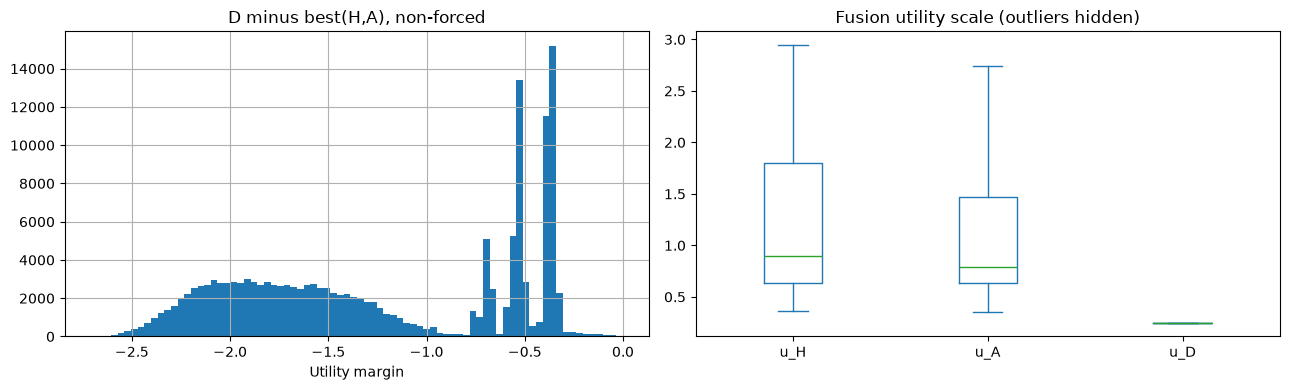

In [4]:
dead = work.loc[~work.is_forced_d].copy()
print(f"Non-forced graded frames: {len(dead):,}")
summary_d = dead.dead_advantage.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("dead_advantage")
display(summary_d)
print("D wins:", int((dead.dead_advantage > 0).sum()),
      "| ties:", int(np.isclose(dead.dead_advantage, 0, atol=1e-9).sum()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dead.dead_advantage.hist(bins=80, ax=axes[0]); axes[0].set_title("D minus best(H,A), non-forced"); axes[0].set_xlabel("Utility margin")
dead[["u_H", "u_A", "u_D"]].plot(kind="box", ax=axes[1], showfliers=False); axes[1].set_title("Fusion utility scale (outliers hidden)")
plt.tight_layout(); plt.show()

In [5]:
def grouped_dead_audit(df, flag):
    z = df.assign(group=df[flag].fillna(False).astype(str))
    return z.groupby("group", dropna=False).agg(
        frames=("frame", "size"), median_margin=("dead_advantage", "median"),
        p95_margin=("dead_advantage", lambda s: s.quantile(.95)),
        d_wins=("dead_advantage", lambda s: (s > 0).sum()),
        median_live=("live_score", "median"), median_dead=("dead_score", "median")
    ).reset_index().assign(condition=flag)
flags = ["stoppage_anchor", "restart_anchor", "out_of_pitch_hint", "is_set_piece_context",
         "ball_observed", "ball_motion_reliable", "motion_reliable"]
display(pd.concat([grouped_dead_audit(dead, f) for f in flags], ignore_index=True)
        [["condition", "group", "frames", "median_margin", "p95_margin", "d_wins", "median_live", "median_dead"]])

,condition,group,frames,median_margin,p95_margin,d_wins,median_live,median_dead
0,stoppage_anchor,0.0,153130,-1.364024,-0.356607,0,0.679477,0.2500
1,stoppage_anchor,0.040000000000000036,114,-0.536460,-0.344071,0,0.586877,0.2628
2,stoppage_anchor,0.07999999999999996,114,-0.530093,-0.331377,0,0.586907,0.2756
3,stoppage_anchor,0.12,114,-0.517766,-0.318789,0,0.587457,0.2884
4,stoppage_anchor,0.16000000000000003,114,-0.513124,-0.306031,0,0.587800,0.3012
...,...,...,...,...,...,...,...,...
59,ball_observed,True,91844,-1.783625,-1.140205,0,0.818232,0.2500
60,ball_motion_reliable,False,64274,-0.501880,-0.340000,0,0.588382,0.2500
61,ball_motion_reliable,True,91649,-1.783944,-1.142429,0,0.818382,0.2500
62,motion_reliable,False,5719,-0.347521,-0.340000,0,0.559676,0.2500


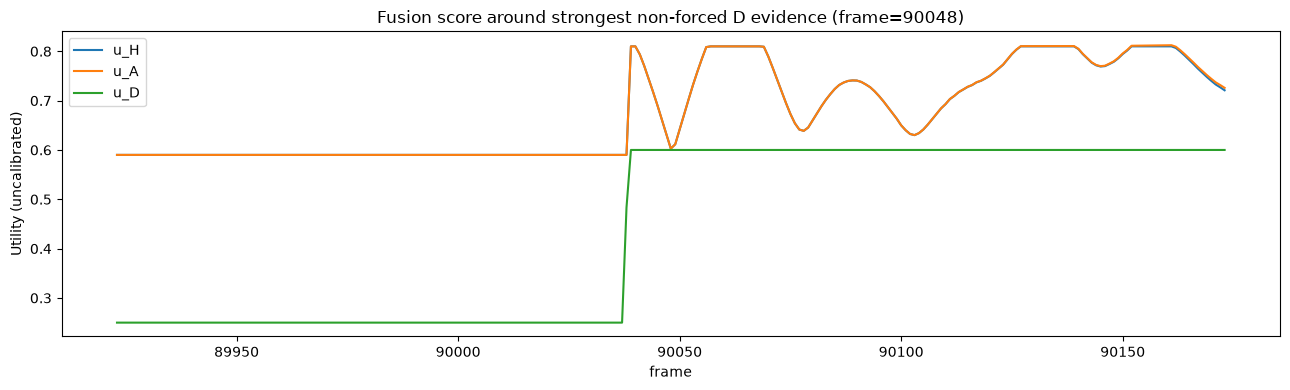

Frame with maximum D advantage: 90048


,frame,half,dead_advantage,u_H,u_A,u_D,live_score,dead_score,stoppage_anchor,restart_anchor
90048,90048,1,-0.002716,0.602716,0.602716,0.60,0.562716,0.60,0.0,0.0
90049,90049,1,-0.011531,0.611531,0.611531,0.60,0.571531,0.60,0.0,0.0
90103,90103,1,-0.030135,0.630056,0.630135,0.60,0.590056,0.60,0.0,0.0
90047,90047,1,-0.031740,0.631740,0.631740,0.60,0.591740,0.60,0.0,0.0
90102,90102,1,-0.032484,0.632411,0.632484,0.60,0.592411,0.60,0.0,0.0
169724,169724,2,-0.032520,0.602520,0.602520,0.57,0.562520,0.57,1.0,0.0
49631,49631,1,-0.032867,0.602867,0.602867,0.57,0.562867,0.57,1.0,0.0
90104,90104,1,-0.034126,0.634040,0.634126,0.60,0.594040,0.60,0.0,0.0
90078,90078,1,-0.038709,0.638709,0.638709,0.60,0.598709,0.60,0.0,0.0
163000,163000,2,-0.038800,0.608800,0.608800,0.57,0.568800,0.57,1.0,0.0


In [6]:
# Jendela dipilih otomatis berdasarkan evidence D relatif terkuat; bukan hand-labelling.
peak_frame = int(dead.loc[dead.dead_advantage.idxmax(), "frame"])
win = frame.loc[frame.frame.between(peak_frame - 125, peak_frame + 125)]
ax = win.plot(x="frame", y=["u_H", "u_A", "u_D"], figsize=(13, 4), title=f"Fusion score around strongest non-forced D evidence (frame={peak_frame})")
ax.set_ylabel("Utility (uncalibrated)"); plt.tight_layout(); plt.show()
print("Frame with maximum D advantage:", peak_frame)
display(dead.nlargest(10, "dead_advantage")[["frame", "half", "dead_advantage", "u_H", "u_A", "u_D", "live_score", "dead_score", "stoppage_anchor", "restart_anchor"]])

**Catatan investigasi 1 (isi setelah menjalankan):**

- Observasi: D tidak pernah menjadi pilihan terbaik lokal di luar interval wajib.
- Hipotesis yang didukung / belum didukung: ketimpangan prior dan konstruksi fusion berkontribusi terhadap lemahnya D.
- Belum terbukti: komponen mana yang paling dominan sepanjang pertandingan, dan apakah bukti stoppage tersedia pada waktu yang tepat.
- Bukti berikutnya: dekomposisi kontribusi skor per kondisi, bukan langsung menaikkan bias D.
- Rekomendasi eksperimen (jangan tuning pada public GT): baru dirancang setelah dekomposisi, dengan satu perubahan terisolasi.

**Arah keputusan investigasi 1**

| Amati | Jika hasilnya seperti ini | Maka arah berikutnya |
|---|---|---|
| Raw dead vs live, lalu utility fusion | Raw D unggul tetapi kalah setelah tambahan kontrol | Investigasi 7: audit keseimbangan fusion |
| Raw dead vs live | Raw D sudah lemah | Investigasi 7: telusuri prior dan bukti dinamis live/dead |
| Bukti D di sekitar event | Hanya berupa pulsa singkat | Investigasi 9: periksa konteks temporal event |

Tidak memilih dead bias baru dari hasil ini. State yang menang utility belum tentu benar secara pertandingan.

## Investigasi 2 — Mengapa H/A sering berganti?

<details><summary><strong>Hipotesis dan interpretasi (klik untuk tampil/sembunyikan)</strong></summary>

Bandingkan tiga tahap: **argmax utility per-frame → decoded label → final label**. Periksa switch rate per babak, margin H/A sebelum/saat/setelah transisi, dan pola A→H→A / H→A→H berdurasi singkat. Peralihan cepat bisa benar; tandai sebagai kandidat analisis, bukan kesalahan pasti.

</details>

In [7]:
def extract_segments(df, label_col):
    """Maximal runs, reset at half boundaries. end_frame inclusive."""
    x = df.sort_values(["half", "frame"])[["half", "frame", label_col]].copy()
    change = (x.half.ne(x.half.shift()) | x[label_col].ne(x[label_col].shift())).cumsum()
    seg = x.groupby(change, sort=False).agg(half=("half", "first"), start_frame=("frame", "first"),
        end_frame=("frame", "last"), label=(label_col, "first"), n_frames=("frame", "size")).reset_index(drop=True)
    seg["duration_s"] = seg.n_frames / 25
    return seg

def switches_per_minute(seg, denominator_frames):
    # Each spell after first in a half starts one state transition.
    return (len(seg) - seg.half.nunique()) / (denominator_frames / 25 / 60)

rows=[]
for col in ["argmax", "decoded_label", "final_label"]:
    ss=extract_segments(work, col)
    for half, part in ss.groupby("half"):
        total_frames = int((work.half == half).sum())
        rows.append(dict(stage=col, half=half, segments=len(part),
                         transitions=max(len(part)-1,0), transitions_per_min=switches_per_minute(part, total_frames),
                         ha_spells=int(part.label.isin(["H","A"]).sum()),
                         ha_lt_2s=int((part.label.isin(["H","A"]) & (part.duration_s < 2)).sum())))
stage_comparison=pd.DataFrame(rows)
display(stage_comparison)

,stage,half,segments,transitions,transitions_per_min,ha_spells,ha_lt_2s
0,argmax,1,856,855,16.138775,856,532
1,argmax,2,854,853,16.116639,853,516
2,decoded_label,1,540,539,10.174035,540,266
3,decoded_label,2,531,530,10.013856,530,260
4,final_label,1,540,539,10.174035,540,265
5,final_label,2,531,530,10.013856,530,258


H/A possession spells: 1070


,count,mean,std,min,10%,50%,90%,max
label,,,,,,,,
A,535.0,4.464523,9.388962,0.24,0.52,1.72,10.656,157.48
H,535.0,7.193271,15.890110,0.28,0.60,2.56,18.936,221.88


H/A spells < 0.5s: 80 / 1070
H/A spells < 1s: 310 / 1070
H/A spells < 2s: 523 / 1070
H/A spells < 3s: 640 / 1070
H/A spells < 5s: 772 / 1070


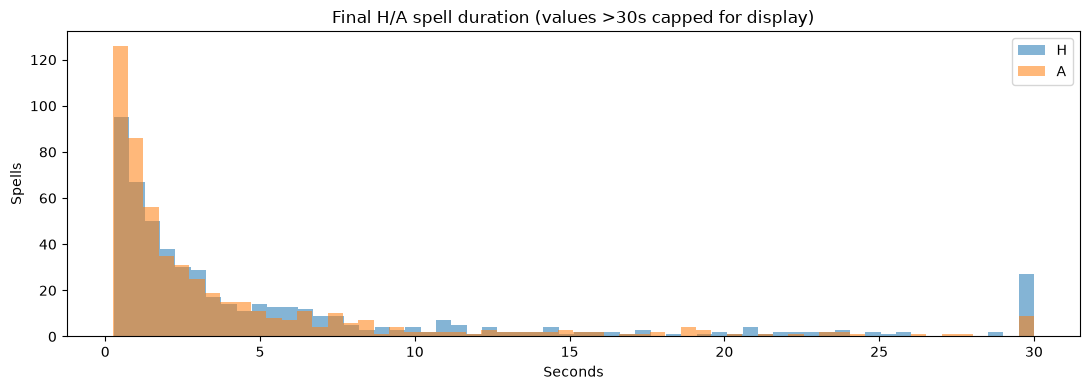

In [8]:
final_segments = extract_segments(work, "final_label")
final_ha = final_segments.loc[final_segments.label.isin(["H", "A"])].copy()
print("H/A possession spells:", len(final_ha))
display(final_ha.groupby("label").duration_s.describe(percentiles=[.1,.5,.9]))
for threshold in [0.5,1,2,3,5]:
    print(f"H/A spells < {threshold}s: {(final_ha.duration_s < threshold).sum()} / {len(final_ha)}")
plt.figure(figsize=(11, 4))
for label in ["H", "A"]:
    plt.hist(final_ha.loc[final_ha.label.eq(label), "duration_s"].clip(upper=30), bins=60, alpha=.55, label=label)
plt.legend(); plt.title("Final H/A spell duration (values >30s capped for display)"); plt.xlabel("Seconds"); plt.ylabel("Spells"); plt.tight_layout(); plt.show()

In [9]:
# Transitions from final spell starts (excluding first segment in each half).
transition_segments = final_segments.loc[final_segments.half.eq(final_segments.half.shift())].copy()
transition_segments["from"] = final_segments.label.shift().loc[transition_segments.index]
transition_segments["to"] = transition_segments.label
transition_segments = transition_segments.rename(columns={"start_frame":"frame"})
transition_table = transition_segments[["half", "frame", "from", "to"]].merge(
    work[["frame", "ha_advantage", "control_margin", "ball_observed", "gap_class", "observation_weight"]], on="frame", how="left", validate="one_to_one")
transition_table["abs_ha_margin"] = transition_table.ha_advantage.abs()
display(transition_table.groupby(["from", "to"], dropna=False).agg(
    transitions=("frame", "size"), median_abs_ha_margin=("abs_ha_margin", "median"),
    ball_observed_rate=("ball_observed", "mean")))
# Detect H->A->H / A->H->A using the middle spell's duration.
s = final_segments
reversal = s.label.eq(s.label.shift(2)) & s.label.ne(s.label.shift(1)) & s.half.eq(s.half.shift(2))
reversal_candidates = s.loc[reversal & s.label.isin(["H","A"])].copy()
reversal_candidates["middle_duration_s"] = s.duration_s.shift(1).loc[reversal_candidates.index]
display(pd.DataFrame({"middle_threshold_s":[.5,1,2,3],
                      "candidate_triplets":[int((reversal_candidates.middle_duration_s < t).sum()) for t in [.5,1,2,3]]}))

,,transitions,median_abs_ha_margin,ball_observed_rate
from,to,,,
A,H,534,0.084066,0.934457
D,H,1,1.443661,1.000000
H,A,534,0.089411,0.956929


,middle_threshold_s,candidate_triplets
0,0.5,80
1,1.0,310
2,2.0,523
3,3.0,639


**Catatan investigasi 2:**

- Apa yang berubah dari raw argmax ke decoded dan final? Decoder membuang banyak pergantian; refinement mempertahankan jumlah pergantian.

- Apakah transisi pendek biasanya terjadi pada margin kecil atau besar? Tabel menunjukkan margin kecil pada seluruh transisi H/A, belum khusus transisi yang membentuk short spell. Pertanyaan khusus short spell belum terjawab.

- Apakah reverse switch terkonsentrasi di kondisi data buruk? Belum diketahui. Notebook belum menghubungkan kandidat reversal dengan kualitas seluruh segmen tengahnya.

Margin kecil tepat di titik transisi juga belum membuktikan bukti lemah: persilangan dua sinyal secara alami dapat melewati margin mendekati nol. Kita perlu melihat persistensi dan akumulasi keunggulan skor sepanjang segmen.

**Arah keputusan investigasi 2**

| Amati | Jika hasilnya seperti ini | Maka arah berikutnya |
|---|---|---|
| Argmax dibanding decoded | Decoder mengurangi transisi | Investigasi 8: audit bukti yang masih mempertahankan short spell |
| Margin pada satu titik transisi | Kecil | Belum cukup; ukur persistensi dan akumulasi sepanjang spell |
| H/A reversal | Banyak | Pisahkan reversal pendek/panjang dan kualitas observasinya; bukan langsung minimum duration |

Reversal harus benar-benar H-A-H/A-H-A dalam satu babak; H-D-H adalah dua possession dengan stoppage.

## Investigasi 3 — Observability & missing-ball behavior

<details><summary><strong>Pertanyaan dan kehati-hatian (klik untuk tampil/sembunyikan)</strong></summary>

Bandingkan laju pergantian state berdasarkan ketersediaan bola, *gap class*, dan durasi gap, dengan denominator exposure yang jelas. Korelasi **tidak membuktikan** missing-ball menyebabkan kesalahan; peristiwa sulit juga dapat menyebabkan bola lebih sering hilang.

</details>

In [10]:
# Rate of final-label switches conditioned on observation regime at the new frame.
x=work.sort_values(["half", "frame"]).copy()
x["switch_final"] = x.final_label.ne(x.final_label.shift()) & x.half.eq(x.half.shift())
x["switch_ha"] = x.switch_final & x.final_label.isin(["H","A"]) & x.final_label.shift().isin(["H","A"])
x["gap_bin"] = pd.cut(x.ball_missing_run_frames.fillna(0)/25,
    bins=[-.001,0, .5,2,10,30,float("inf")], labels=["observed", "0–0.5s", "0.5–2s", "2–10s", "10–30s", ">30s"])
def switch_rate(df, by):
    z=df.groupby(by, observed=False, dropna=False).agg(frames=("frame","size"),
         switches=("switch_final","sum"), ha_switches=("switch_ha","sum"),
         mean_observation_weight=("observation_weight","mean"))
    z["switches_per_min"] = z.switches / z.frames * 25 * 60
    z["ha_switches_per_min"] = z.ha_switches / z.frames * 25 * 60
    return z.reset_index()
display(switch_rate(x,"gap_bin"))
display(switch_rate(x,"ball_motion_reliable"))
display(switch_rate(x,"motion_reliable"))

,gap_bin,frames,switches,ha_switches,mean_observation_weight,switches_per_min,ha_switches_per_min
0,observed,94214,1011,1010,0.986478,16.096334,16.080413
1,0–0.5s,53,1,1,0.339668,28.301887,28.301887
2,0.5–2s,22,0,0,0.279203,0.000000,0.000000
3,2–10s,9465,24,24,0.340187,3.803487,3.803487
4,10–30s,26770,24,24,0.323470,1.344789,1.344789
5,>30s,28333,9,9,0.263743,0.476476,0.476476


,ball_motion_reliable,frames,switches,ha_switches,mean_observation_weight,switches_per_min,ha_switches_per_min
0,False,64942,96,96,0.301664,2.217363,2.217363
1,True,93915,973,972,0.987332,15.540648,15.524677


,motion_reliable,frames,switches,ha_switches,mean_observation_weight,switches_per_min,ha_switches_per_min
0,False,5870,1,1,0.129813,0.255537,0.255537
1,True,152987,1068,1067,0.729173,10.471478,10.461673


In [11]:
gaps = load_table("diagnostics/features_initial/missing_ball_gaps.csv")
# Missing-gap table uses inclusive ends. Count switches in gap and compare by duration.
gap_records=[]
for r in gaps.itertuples(index=False):
    window=x.loc[x.half.eq(r.half) & x.frame.between(r.start_frame,r.end_frame)]
    gap_records.append({"half":r.half,"start_frame":r.start_frame,"end_frame":r.end_frame,
                        "duration_s":r.duration_s,"frames":len(window),
                        "ha_switches":int(window.switch_ha.sum()),
                        "switches_per_min":float(window.switch_ha.sum())/(len(window)/25/60) if len(window) else np.nan})
gap_diagnostics=pd.DataFrame(gap_records)
display(gap_diagnostics.describe(percentiles=[.5,.9,.95]))
display(gap_diagnostics.nlargest(10,"ha_switches"))

,half,start_frame,end_frame,duration_s,frames,ha_switches,switches_per_min
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,1.540000,106899.933333,107329.886667,17.238133,430.953333,0.386667,3.052525
std,0.500067,54546.064142,54553.359249,23.868929,596.723237,0.599627,12.756532
min,1.000000,11185.000000,11186.000000,0.040000,1.000000,0.000000,0.000000
50%,2.000000,118657.000000,118936.000000,10.720000,268.000000,0.000000,0.000000
90%,2.000000,178907.500000,179073.500000,33.812000,845.300000,1.000000,8.305156
95%,2.000000,183300.500000,183573.900000,50.796000,1269.900000,2.000000,11.074346
max,2.000000,190076.000000,190197.000000,221.480000,5537.000000,2.000000,150.000000


,half,start_frame,end_frame,duration_s,frames,ha_switches,switches_per_min
57,1,79293,79514,8.88,222,2,13.513514
82,2,123369,123748,15.20,380,2,7.894737
93,2,135624,136678,42.20,1055,2,2.843602
101,2,142615,143076,18.48,462,2,6.493506
106,2,147511,147642,5.28,132,2,22.727273
116,2,163720,163964,9.80,245,2,12.244898
129,2,173371,173881,20.44,511,2,5.870841
133,2,177984,178177,7.76,194,2,15.463918
145,2,187127,187263,5.48,137,2,21.897810
5,1,17460,17825,14.64,366,1,4.098361


**Catatan investigasi 3:**

- Switch rate tertinggi? Secara numerik, bin gap 0–0,5 detik mencapai 28,30 per menit. Tetapi denominatornya hanya 53 frame atau 2,12 detik, dengan satu switch. Angka ini tidak stabil. Kelompok observed yang jauh lebih besar memberikan temuan lebih kuat.
- Apakah bertahan per babak? Belum diuji melalui tabulasi observability × babak. Tabel sebelumnya hanya menunjukkan laju transisi total kedua babak relatif serupa.
- Apakah berbeda menurut durasi gap? Secara deskriptif, gap panjang memiliki laju pergantian lebih rendah.
- Variabel pengganggu? Fase permainan, stoppage, lokasi bola, cakupan tag, interval forced-D, dan perubahan bukti ketika bola menghilang atau muncul kembali.

Kestabilan saat missing ball belum berarti prediksinya benar. Model mungkin mempertahankan state karena informasi melemah. Investigasi berikutnya perlu melihat awal, tengah, akhir gap, serta saat bola muncul kembali.

**Arah keputusan investigasi 3**

| Amati | Jika hasilnya seperti ini | Maka arah berikutnya |
|---|---|---|
| Switch rate dengan exposure memadai | Lebih tinggi saat observed | Investigasi 8: periksa geometri/kontrol ketika bukti tersedia |
| Awal/akhir gap | Switch terkonsentrasi saat visibility berubah | Pertimbangkan pengujian kesinambungan bukti atau quality-aware inference setelah diagnosis |
| Gap panjang | Stabil | Jangan menyebut benar; bisa berarti sistem kekurangan informasi |
| Rate sangat tinggi pada sedikit frame | Exposure kecil | Laporkan ukuran sampel; jangan jadikan dasar perubahan parameter |

Perbandingan per babak dan forced-D perlu dipisahkan. Korelasi observability bukan bukti kesalahan atau sebab kausal.

## Investigasi 4 — Smart Tagging & event anchors

<details><summary><strong>Tujuan (klik untuk tampil/sembunyikan)</strong></summary>

Analisis *agreement/disagreement* sumber evidence. `events.csv` berisi interval **[start_frame, end_frame)**, berbeda dari tabel segmen yang memakai akhir **inklusif**. Tag attacking phase tidak selalu identik dengan possession, dan event candidate bukan GT.

</details>

In [12]:
# How often does the observed team proxy / final prediction agree with contextual attacking tags?
tagged=x.loc[x.active_h_tags.fillna(0).gt(0) ^ x.active_a_tags.fillna(0).gt(0)].copy()
tagged["single_tag_side"] = np.where(tagged.active_h_tags.fillna(0).gt(0), "H", "A")
tagged["tag_agrees_final"] = tagged.single_tag_side.eq(tagged.final_label)
tagged["tag_agrees_proxy"] = tagged.single_tag_side.eq(tagged.nearest_team_proxy)
display(tagged.groupby("single_tag_side").agg(frames=("frame","size"),
      agrees_final=("tag_agrees_final","mean"), agrees_proxy=("tag_agrees_proxy","mean")))
print("Frames with unambiguous attacking-team tag:",len(tagged))
print("Agreement rates describe consistency between algorithmic signals, NOT accuracy")

,frames,agrees_final,agrees_proxy
single_tag_side,,,
A,25665,0.597662,0.241262
H,30901,0.843209,0.203521


Frames with unambiguous attacking-team tag: 56566
Agreement rates describe consistency between algorithmic signals, NOT accuracy


In [13]:
candidates=load_table(f"core/{CORE_PASS}/events/candidates.csv")
print("Event candidates:",len(candidates))
display(candidates.groupby(["event","source"],dropna=False).size().rename("count").reset_index())
# One frame per candidate; duplicate candidate frames are allowed, not counted as independent ground-truth events.
annotated_candidates = candidates.merge(work[["frame", "dead_advantage", "u_D", "stoppage_anchor", "restart_anchor", "final_label"]],
                                      on="frame", how="left", validate="many_to_one")
display(annotated_candidates.groupby("event",dropna=False).agg(
    candidates=("frame","size"), median_dead_advantage=("dead_advantage","median"),
    max_dead_advantage=("dead_advantage","max")))

Event candidates: 117


,event,source,count
0,set_piece_end,smart_tagging,59
1,set_piece_start,smart_tagging,58


,candidates,median_dead_advantage,max_dead_advantage
event,,,
set_piece_end,59,-1.540561,-2.350682e-01
set_piece_start,58,-0.233626,2.000000e+06


**Catatan investigasi 4:**

- Apakah anchor berkaitan dengan peningkatan D evidence? Rumus memang menambahkan bukti D di sekitar anchor. Tabel kandidat juga menunjukkan median dead advantage set-piece start lebih dekat ke nol daripada set-piece end. Tetapi keduanya bukan kelompok terkontrol, sehingga belum mengisolasi pengaruh anchor.
- Apakah konsistensi tag berbeda saat bola observed/missing? Belum dijawab; tabel agreement belum dipisahkan menurut kondisi tersebut.
- Apakah event evidence berguna? Ada pengaruh terhadap skor, tetapi efektivitas dan ketepatan waktunya belum terbukti.

**Arah keputusan investigasi 4**

| Amati | Jika hasilnya seperti ini | Maka arah berikutnya |
|---|---|---|
| Tag aktif mentah | Mencampur attacking dan defending | Investigasi 9: klasifikasikan peran tag dahulu |
| Agreement proxy | Banyak proxy tidak tersedia | Pisahkan availability dari agreement pada proxy yang tersedia |
| Utility D pada anchor | Nilai sangat besar dari forced-D | Keluarkan forced interval dan seluruh jendela profil yang menyentuhnya |
| Event profile alami | D naik tetapi tetap kalah | Gabungkan diagnosis event dengan dekomposisi Investigasi 7 |

Agreement antar-prediksi bukan accuracy; anchor juga bukan waktu restart ground truth.

## Investigasi 5 — Decoder & boundary refinement

<details><summary><strong>Pertanyaan (klik untuk tampil/sembunyikan)</strong></summary>

Dari argmax → decoded → refined, identifikasi seberapa banyak keputusan berubah. Decoder dapat mengabaikan state terbaik lokal karena biaya transisi. Refinement dapat menggeser boundary tanpa mengurangi jumlah spell. Jangan menyamakan jumlah merge eksplisit dengan besarnya efek penalti durasi.

</details>

In [14]:
print("Disagreement per graded frame")
display(pd.DataFrame({
    "comparison":["argmax vs decoder", "decoder vs final", "argmax vs final"],
    "disagreement_frames":[int((work.argmax != work.decoded_label).sum()),
        int((work.decoded_label != work.final_label).sum()), int((work.argmax != work.final_label).sum())],
    "fraction":[(work.argmax != work.decoded_label).mean(),
        (work.decoded_label != work.final_label).mean(), (work.argmax != work.final_label).mean()]}))
boundary_report=load_table("boundary/report.csv")
display(boundary_report.describe(include="all"))
display(boundary_report.groupby("ambiguous",dropna=False).agg(
    boundaries=("shift_frames","size"), moved=("shift_frames",lambda s: (s != 0).sum()),
    median_abs_shift=("shift_frames",lambda s: s.abs().median()),
    p95_abs_shift=("shift_frames",lambda s: s.abs().quantile(.95))))

Disagreement per graded frame


,comparison,disagreement_frames,fraction
0,argmax vs decoder,10513,0.066179
1,decoder vs final,115,0.000724
2,argmax vs final,10398,0.065455


,half,original_frame,refined_frame,shift_frames,from,to,ambiguous
count,1069.000000,1069.000000,1069.000000,1069.000000,1069,1069,1069
unique,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,A,H,False
freq,NaN,NaN,NaN,NaN,534,535,1049
mean,1.495790,97104.895229,97104.903648,0.008419,NaN,NaN,NaN
std,0.500216,56513.418823,56513.436332,0.328035,NaN,NaN,NaN
min,1.000000,11242.000000,11242.000000,-1.000000,NaN,NaN,NaN
25%,1.000000,42810.000000,42810.000000,0.000000,NaN,NaN,NaN
50%,1.000000,88543.000000,88543.000000,0.000000,NaN,NaN,NaN
75%,2.000000,145963.000000,145963.000000,0.000000,NaN,NaN,NaN


,boundaries,moved,median_abs_shift,p95_abs_shift
ambiguous,,,,
False,1049,115,0.0,1.0
True,20,0,0.0,0.0


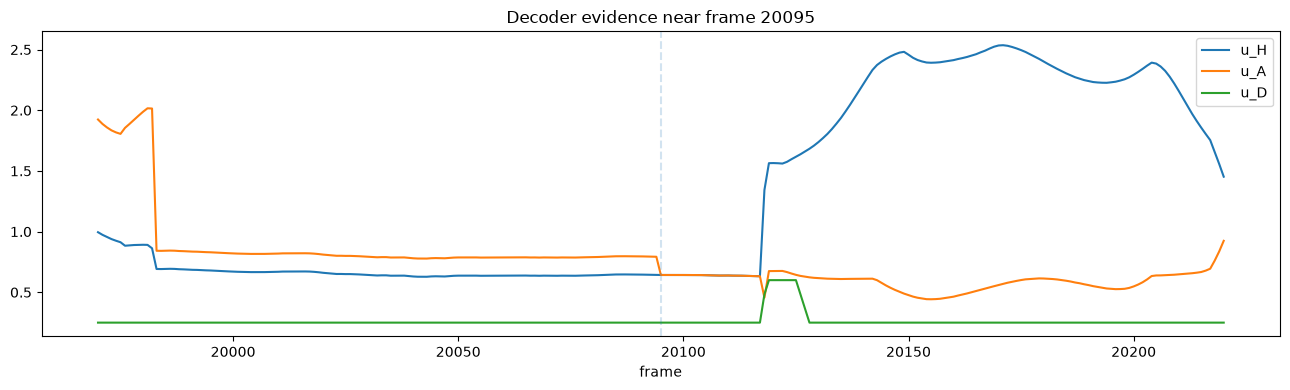

,frame,u_H,u_A,u_D,argmax,decoded_label,final_label
19970,19970,0.995044,1.923694,0.25,A,A,A
19971,19971,0.973333,1.886972,0.25,A,A,A
19972,19972,0.955401,1.858113,0.25,A,A,A
19973,19973,0.938301,1.834172,0.25,A,A,A
19974,19974,0.924696,1.817394,0.25,A,A,A
19975,19975,0.912466,1.805335,0.25,A,A,A
19976,19976,0.883652,1.854986,0.25,A,A,A
19977,19977,0.886515,1.887486,0.25,A,A,A
19978,19978,0.889399,1.921746,0.25,A,A,A
19979,19979,0.890750,1.955001,0.25,A,A,A


In [15]:
# For any selected frame, show evidence and labels around it, without editing labels.
INSPECT_FRAME = int(transition_table.loc[transition_table.abs_ha_margin.idxmin(), "frame"]) if len(transition_table) else 11185
RADIUS_FRAMES = 125
zoom = frame.loc[frame.frame.between(INSPECT_FRAME-RADIUS_FRAMES, INSPECT_FRAME+RADIUS_FRAMES)]
ax=zoom.plot(x="frame", y=["u_H", "u_A", "u_D"], figsize=(13,4), title=f"Decoder evidence near frame {INSPECT_FRAME}")
for f in zoom.loc[zoom.final_label.ne(zoom.final_label.shift()),"frame"].iloc[1:]:
    ax.axvline(f, alpha=.2, linestyle="--")
plt.tight_layout();plt.show()
display(zoom[["frame", "u_H", "u_A", "u_D", "argmax", "decoded_label", "final_label"]].head(12))

**Catatan investigasi 5:**

- Decoder mengurangi atau meningkatkan pergantian? Mengurangi: 1.708 menjadi 1.069.
- Seberapa besar efek refinement? Kecil pada run ini: 115 frame berubah, tanpa pengurangan segmen.
- Apakah pergeseran didukung evidence yang jelas? Belum dapat dipastikan dari output sekarang. Perlu membandingkan objective atau keunggulan bukti sebelum/sesudah pergeseran. Flag ambiguous=False bukan bukti bahwa batas tersebut benar.

**Arah keputusan investigasi 5**

| Amati | Jika hasilnya seperti ini | Maka arah berikutnya |
|---|---|---|
| Utility vs biaya pergantian | Keuntungan besar | Investigasi 10: decoder mungkin mengikuti skor; prioritaskan scoring |
| Utility vs biaya pergantian | Keuntungan mendekati biaya | Kandidat eksperimen sensitivitas biaya setelah skenario sintetis disiapkan |
| Boundary refinement | Hanya menggeser batas tanpa mengubah count | Jangan menjadikannya solusi utama fragmentasi |
| Klaim objective lokal bertentangan dengan decoded | Ada net gain negatif | Periksa indeks, hint, versi kode, dan postprocessing sebelum menyebut bug |

Jumlah explicit short-run merge bukan ukuran seluruh efek temporal Viterbi.

## Investigasi 6 — Perbandingan eksperimen (siap diperluas)

<details><summary><strong>Protokol eksperimen (klik untuk tampil/sembunyikan)</strong></summary>

Gunakan run terpisah untuk setiap perubahan yang mempunyai hipotesis jelas. Bandingkan *behavior diagnostics* secara agregat, bukan public-GT tuning. Perubahan segment count atau dead fraction **bukan bukti** peningkatan spellF1.

`COMPARE_RUN_ID = None` berarti investigasi ini dilewati. Setelah kamu memiliki run baru, isi ID lalu jalankan cell di bawah. Jangan mengubah source artifact.

</details>

In [29]:
COMPARE_RUN_ID = "20261115_213258_734998_6f1c5833"  # contoh: "20261115_......" (run completed lain)

def summarize_run(run_dir):
    m=read_json(run_dir)
    final = read_table(run_dir, "result/labels.csv")
    feature = read_table(run_dir, "features/initial/frames.csv")[["frame", "half", "graded"]]
    merged = feature.merge(final[["frame", "label"]], on="frame", validate="one_to_one")
    selected = merged.loc[merged.graded.astype(bool)]
    segments = extract_segments(selected, "label")
    h_a = segments[segments.label.isin(["H", "A"])]
    return dict(run_id=m["run_id"], core_pass=m["final_core_pass"],
        possessions=len(h_a), ha_short_lt_2s=int((h_a.duration_s<2).sum()),
        ha_short_fraction=float((h_a.duration_s<2).mean()),
        dead_frames=int(selected.label.eq("D").sum()),
        dead_fraction=float(selected.label.eq("D").mean()),
        transitions=int(len(segments) - segments.half.nunique()))

if COMPARE_RUN_ID is None:
    print("Perbandingan dilewati. Isi COMPARE_RUN_ID setelah ada run lain.")
else:
    candidate_dir = next((Path(r["path"]) for r in runs if r["run_id"] == COMPARE_RUN_ID), None)
    if candidate_dir is None:
        raise ValueError("COMPARE_RUN_ID tidak ditemukan dalam completed runs")
    display(pd.DataFrame([summarize_run(RUN_DIR), summarize_run(candidate_dir)]))

ValueError: COMPARE_RUN_ID tidak ditemukan dalam completed runs

**Log eksperimen (tambahkan catatan setiap run):**

| Run ID | Perubahan tunggal | Hipotesis | Perilaku yang berubah | Risiko / keputusan |
|---|---|---|---|---|
| `...` | — | — | — | — |

**Catatan:** Tidak ada metric ground truth privat di notebook ini. Indikator perilaku bersifat diagnostik, bukan penentu skor resmi.

**Arah keputusan investigasi 6 (eksperimen belum dijalankan)**

| Syarat/hasil | Keputusan |
|---|---|
| Mekanisme belum terisolasi | Lanjutkan Investigasi 7–10; jangan mengubah banyak bobot sekaligus |
| Hipotesis spesifik dan dapat diuji | Satu perubahan pada satu run baru; baseline tetap disimpan |
| Count possession/dead fraction berubah | Nilai sebagai perubahan perilaku, bukan bukti kenaikan spellF1 |
| Perilaku target membaik tetapi skenario sintetis lain rusak | Revisi atau tolak perubahan |

Catat observasi, hipotesis, perubahan tunggal, ekspektasi, hasil, efek samping, dan batas simpulan. Tidak memakai public GT untuk memilih model.

## Investigasi 7 — Mengapa D kalah: raw evidence atau tambahan kontrol?

**Pertanyaan:** Apakah D sudah kalah pada raw live/dead evidence, atau baru tertinggal setelah kontrol tim masuk ke fusion?

**Data:** snapshot config, feature snapshot yang sesuai `final_core_pass`, serta return quality, control, live/dead, event, fusion dan decoder. Semua join harus one-to-one pada frame dan mencakup seluruh frame.

**Metode:** bandingkan `raw_dead_minus_live`, `pre_control_dead_advantage`, dan `dead_advantage`; kelompokkan menurut observability, babak dan anchor; ukur rangkaian dukungan positif. `pre_control` adalah identitas diagnostik dari utility tersimpan, **bukan model alternatif atau label baru**.

**Batas dekomposisi:** artefak belum memisahkan kontribusi individual jarak/margin/tag maupun setiap bonus live/dead. Kita hanya memisahkan channel yang tersedia dan total bonus di atas prior. Atribusi individual memerlukan instrumentasi di src, tidak menyalin implementasi scoring ke notebook.


In [17]:
from pathlib import Path
import sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
RC_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").is_file())
if str(RC_ROOT) not in sys.path:
    sys.path.insert(0, str(RC_ROOT))
from src.artifacts import list_runs, read_json, read_table
import games
RC_RUN_ID = globals().get("RUN_ID", "20261115_152745_650609_05d95801")
rc_runs = list_runs(project_dir=RC_ROOT)
rc_path = (Path(rc_runs[-1]["path"]) if RC_RUN_ID is None else
           next(Path(r["path"]) for r in rc_runs if r["run_id"] == RC_RUN_ID))
rc_manifest = read_json(rc_path)
rc_cfg = read_json(rc_path, "config/model.json")
rc_pass = rc_manifest["final_core_pass"]
rc_fps = float(rc_cfg["fps"])
rc_feature_path = "features/refreshed/result.csv" if rc_pass == "after_video" else "features/initial/frames.csv"
rc_all = read_table(rc_path, rc_feature_path).sort_values("frame").reset_index(drop=True)
assert np.array_equal(rc_all.frame.to_numpy(), np.arange(len(rc_all))), "Timeline fitur tidak kanonis"

def rc_join(base, relative, rename=None):
    source = read_table(rc_path, relative).rename(columns=rename or {}).sort_values("frame")
    assert source.frame.is_unique, f"Duplicate key: {relative}"
    assert np.array_equal(base.frame.to_numpy(), source.frame.to_numpy()), f"Missing/extra frame: {relative}"
    assert not ((set(base.columns) & set(source.columns)) - {"frame"}), f"Column collision: {relative}"
    return base.merge(source, on="frame", how="left", validate="one_to_one", sort=False)

for relative, rename in [
    (f"core/{rc_pass}/quality/frames.csv", None),
    (f"core/{rc_pass}/control/frames.csv", None),
    (f"core/{rc_pass}/live_dead/frames.csv", None),
    (f"core/{rc_pass}/events/frames.csv", None),
    (f"core/{rc_pass}/fusion/state_log_scores.csv", {"H":"u_H", "A":"u_A", "D":"u_D"}),
    (f"core/{rc_pass}/decode/labels.csv", {"label":"decoded_label"}),
    ("result/labels.csv", {"label":"final_label"})]:
    rc_all = rc_join(rc_all, relative, rename)
rc_start2 = next(s for h,s,e in games.half_video_blocks(rc_cfg["game"]) if h == 2)
rc_kickoff2 = int(rc_cfg["fusion"]["second_half_kickoff_frame"])
rc_all["forced_d"] = rc_all.half.eq(2) & rc_all.frame.between(rc_start2, rc_kickoff2-1)
rc_all["best_team_utility"] = rc_all[["u_H", "u_A"]].max(axis=1)
rc_all["raw_dead_minus_live"] = rc_all.dead_score - rc_all.live_score
rc_all["live_reference"] = float(rc_cfg["fusion"]["live_weight"]) * rc_all.live_score
rc_all["control_addition"] = rc_all.best_team_utility - rc_all.live_reference
rc_all["pre_control_dead_advantage"] = rc_all.u_D - rc_all.live_reference
rc_all["dead_advantage"] = rc_all.u_D - rc_all.best_team_utility
rc_all["live_dynamic_bonus"] = rc_all.live_score - float(rc_cfg["live_dead"]["live_prior_score"])
rc_all["dead_dynamic_bonus"] = rc_all.dead_score - float(rc_cfg["live_dead"]["dead_prior_score"])
rc_d = rc_all.loc[rc_all.graded & ~rc_all.forced_d].copy()
assert np.isfinite(rc_d[["u_H","u_A","u_D"]]).all().all()
np.testing.assert_allclose(rc_d.dead_advantage,
    rc_d.pre_control_dead_advantage - rc_d.control_addition, atol=1e-10)
np.testing.assert_allclose(rc_d.control_addition,
    float(rc_cfg["fusion"]["team_weight"]) * rc_d[["h_control_score","a_control_score"]].max(axis=1), atol=1e-10)
rc_d["anchor_regime"] = np.select([
    (rc_d.stoppage_anchor > 0) & (rc_d.restart_anchor > 0),
    rc_d.stoppage_anchor > 0, rc_d.restart_anchor > 0],
    ["both", "stoppage", "restart"], default="none")
rc_d["outside_support"] = rc_d.out_of_pitch_hint > 0
print("Run:", rc_manifest["run_id"], "core:", rc_pass,
      "natural graded:", len(rc_d), "forced graded:", int((rc_all.graded & rc_all.forced_d).sum()))
display(read_json(rc_path, "config/model.json")["fusion"])


Run: 20261115_152745_650609_05d95801 core: initial natural graded: 155923 forced graded: 2934


{'team_weight': 1.0,
 'live_weight': 1.0,
 'dead_weight': 1.0,
 'dead_bias': 0.0,
 'second_half_kickoff_frame': 113742}

,count,mean,std,min,5%,50%,95%,99%,max
raw_dead_minus_live,155923.0,-0.447585,0.130253,-0.640000,-0.640000,-0.420000,-0.305320,-0.107146,0.277576
pre_control_dead_advantage,155923.0,-0.447585,0.130253,-0.640000,-0.640000,-0.420000,-0.305320,-0.107146,0.277576
dead_advantage,155923.0,-1.233802,0.699897,-2.706399,-2.260336,-1.347058,-0.354429,-0.340000,-0.002716
live_score,155923.0,0.706991,0.119080,0.550000,0.564130,0.674260,0.890000,0.890000,0.890000
dead_score,155923.0,0.259405,0.050601,0.250000,0.250000,0.250000,0.250000,0.600000,0.920000
control_addition,155923.0,0.786216,0.612004,0.040000,0.040000,0.813760,1.739628,1.885412,2.081476
live_dynamic_bonus,155923.0,0.156991,0.119080,0.000000,0.014130,0.124260,0.340000,0.340000,0.340000
dead_dynamic_bonus,155923.0,0.009405,0.050601,0.000000,0.000000,0.000000,0.000000,0.350000,0.670000


,comparison,frames,positive_frames,tie_frames,median,max
0,raw_dead_minus_live,155923,169,0,-0.420000,0.277576
1,pre_control_dead_advantage,155923,169,0,-0.420000,0.277576
2,dead_advantage,155923,0,0,-1.347058,-0.002716


D beats best team utility,False
D beats live_reference,
False,155754
True,169


,half,ball_observed,anchor_regime,outside_support,frames,median_raw,median_pre_control,median_fused,median_control_addition,raw_D_wins,fused_D_wins,exposure_s
0,1,False,none,False,31079,-0.339621,-0.339621,-0.507963,0.190000,0,0,1243.16
1,1,False,none,True,11,-0.358017,-0.358017,-0.568003,0.190000,0,0,0.44
2,1,False,restart,False,341,-0.275532,-0.275532,-0.376013,0.040000,0,0,13.64
3,1,False,stoppage,False,872,-0.171769,-0.171769,-0.341616,0.190000,4,0,34.88
4,1,False,stoppage,True,1,-0.110361,-0.110361,-0.150361,0.040000,0,0,0.04
5,1,True,none,False,44965,-0.567668,-0.567668,-1.805899,1.266683,0,0,1798.60
6,1,True,none,True,815,-0.168556,-0.168556,-0.956724,0.805397,7,0,32.60
7,1,True,restart,False,982,-0.450947,-0.450947,-1.832507,1.390053,0,0,39.28
8,1,True,stoppage,False,287,-0.236288,-0.236288,-1.567411,1.359111,19,0,11.48
9,1,True,stoppage,True,114,0.043510,0.043510,-0.827636,0.916084,70,0,4.56


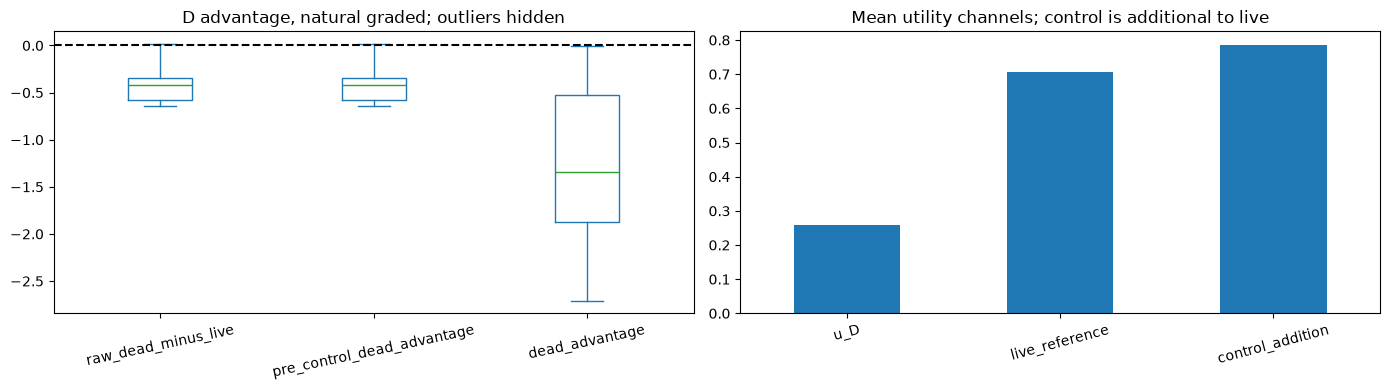

In [18]:
rc_adv_cols = ["raw_dead_minus_live", "pre_control_dead_advantage", "dead_advantage"]
display(rc_d[rc_adv_cols + ["live_score", "dead_score", "control_addition",
    "live_dynamic_bonus", "dead_dynamic_bonus"]].describe(percentiles=[.05,.5,.95,.99]).T)
rc_7_counts = pd.DataFrame([{
    "comparison": col, "frames": len(rc_d), "positive_frames": int((rc_d[col] > 1e-9).sum()),
    "tie_frames": int((rc_d[col].abs() <= 1e-9).sum()), "median": rc_d[col].median(), "max": rc_d[col].max()
} for col in rc_adv_cols])
display(rc_7_counts)
display(pd.crosstab(rc_d.pre_control_dead_advantage.gt(1e-9).rename("D beats live_reference"),
                    rc_d.dead_advantage.gt(1e-9).rename("D beats best team utility")))
rc_7_groups = rc_d.groupby(["half", "ball_observed", "anchor_regime", "outside_support"], observed=True).agg(
    frames=("frame","size"), median_raw=("raw_dead_minus_live","median"),
    median_pre_control=("pre_control_dead_advantage","median"), median_fused=("dead_advantage","median"),
    median_control_addition=("control_addition","median"),
    raw_D_wins=("raw_dead_minus_live", lambda s: int((s > 1e-9).sum())),
    fused_D_wins=("dead_advantage", lambda s: int((s > 1e-9).sum()))).reset_index()
rc_7_groups["exposure_s"] = rc_7_groups.frames / rc_fps
display(rc_7_groups)
fig, axes = plt.subplots(1,2,figsize=(14,4))
rc_d[rc_adv_cols].plot.box(ax=axes[0], showfliers=False, rot=12)
axes[0].axhline(0, color="black", ls="--"); axes[0].set_title("D advantage, natural graded; outliers hidden")
rc_d[["u_D","live_reference","control_addition"]].mean().plot.bar(ax=axes[1], rot=15)
axes[1].set_title("Mean utility channels; control is additional to live")
plt.tight_layout(); plt.show()


In [19]:
def rc_positive_runs(df, column, threshold=1e-9):
    z = df.sort_values(["half","frame"]).copy()
    positive = z[column] > threshold
    boundary = (z.half.ne(z.half.shift()) | z.frame.diff().ne(1) | positive.ne(positive.shift()))
    group = boundary.cumsum()
    rows=[]
    for _, part in z.loc[positive].groupby(group[positive]):
        rows.append({"half":int(part.half.iloc[0]), "start_frame":int(part.frame.iloc[0]),
                     "end_frame":int(part.frame.iloc[-1]), "n_frames":len(part), "duration_s":len(part)/rc_fps})
    return pd.DataFrame(rows, columns=["half","start_frame","end_frame","n_frames","duration_s"])
rc_7_runs = {col:rc_positive_runs(rc_d,col) for col in rc_adv_cols}
display(pd.DataFrame([{"comparison":col,"positive_runs":len(g),
    "median_duration_s":g.duration_s.median(),"max_duration_s":g.duration_s.max()}
    for col,g in rc_7_runs.items()]))
rc_7_pre_wins = int((rc_d.pre_control_dead_advantage > 1e-9).sum())
rc_7_fused_wins = int((rc_d.dead_advantage > 1e-9).sum())
rc_7_lost = int(((rc_d.pre_control_dead_advantage > 1e-9) & (rc_d.dead_advantage <= 1e-9)).sum())
display(Markdown(f"**Temuan run ini:** D mengalahkan live_reference pada **{rc_7_pre_wins:,}** frame alami; "
    f"**{rc_7_lost:,}** frame tersebut tidak lagi menang sesudah tambahan kontrol. D menang terhadap tim terbaik pada **{rc_7_fused_wins:,}** frame. "
    "Ini mengukur mekanisme kompetisi skor, bukan jumlah frame dead-ball yang benar. "
    "Tabel kelompok dan durasi menentukan apakah masalah dominan raw evidence, tambahan kontrol, atau keduanya."))

display(Markdown(f"**Interpretasi:** peluang D menang sebelum tambahan kontrol mencakup {rc_7_pre_wins/len(rc_d):.3%} exposure alami. "
      "Fusion menekan peluang tersebut, tetapi angka ini belum membuktikan bahwa mengubah fusion saja cukup: "
      "bukti dead vs live dan durasi dukungannya tetap perlu diperiksa. "
      "Sebagian besar frame dapat benar-benar live; kekalahan raw D bukan dengan sendirinya error."))


,comparison,positive_runs,median_duration_s,max_duration_s
0,raw_dead_minus_live,21,0.12,1.52
1,pre_control_dead_advantage,21,0.12,1.52
2,dead_advantage,0,NaN,NaN


**Temuan run ini:** D mengalahkan live_reference pada **169** frame alami; **169** frame tersebut tidak lagi menang sesudah tambahan kontrol. D menang terhadap tim terbaik pada **0** frame. Ini mengukur mekanisme kompetisi skor, bukan jumlah frame dead-ball yang benar. Tabel kelompok dan durasi menentukan apakah masalah dominan raw evidence, tambahan kontrol, atau keduanya.

**Interpretasi:** peluang D menang sebelum tambahan kontrol mencakup 0.108% exposure alami. Fusion menekan peluang tersebut, tetapi angka ini belum membuktikan bahwa mengubah fusion saja cukup: bukti dead vs live dan durasi dukungannya tetap perlu diperiksa. Sebagian besar frame dapat benar-benar live; kekalahan raw D bukan dengan sendirinya error.

**Interpretasi dan arah keputusan — Investigasi 7**

| Jika terlihat | Kemungkinan mekanisme | Keputusan berikutnya |
|---|---|---|
| Pre-control D positif tetapi fused D negatif | Tambahan kontrol mengubah pemenang lokal | Kandidat eksperimen terisolasi pada struktur/bobot fusion; belum memilih nilainya |
| Raw D dan pre-control D sudah negatif pada hampir semua exposure | Kelemahan sebelum tambahan kontrol | Instrumentasi kontribusi prior, gerak, dan event di src sebelum eksperimen |
| Dukungan positif hanya berupa run sangat pendek | Pulsa event tidak menopang interval | Gabungkan dengan profil anchor di Investigasi 9 |
| D mendekati live hanya saat outside_support | Ketergantungan pada satu bukti | Periksa cakupan bukti stoppage lain; out-of-pitch juga bisa noise |
| Hasil berbeda antar babak/observability | Efek kondisional | Jangan menyimpulkan dari agregat saja |

**Batas simpulan:** pengurangan skor kontrol bukan rekomendasi langsung. Total bonus di atas prior belum menjelaskan komponen bonus mana yang dominan. Frame berurutan berkorelasi; banyak frame bukan banyak sampel independen. Jika efek hanya muncul pada sedikit event, bawa ketidakpastian itu ke eksperimen.


## Investigasi 8 — Mekanisme short spell dan H/A reversal

**Pertanyaan:** Bukti apa yang mempertahankan segmen pendek setelah decoder? Apakah terkait geometri, tag, persistensi proxy, atau perubahan visibility?

**Data:** segmen decoded sebelum refinement dan frame-level output pada core pass yang sama.

**Metode:** ukur seluruh segmen, bukan hanya margin pada frame awal. Bandingkan kelompok durasi; identifikasi H-A-H/A-H-A dalam babak yang sama, dengan ketiga label H/A. Ambang durasi di sini hanya kategori deskriptif, bukan minimum duration model.


In [20]:
rc_decoded_segments = read_table(rc_path, f"diagnostics/{rc_pass}/prediction/segments.csv").copy()
assert (rc_decoded_segments.end_frame-rc_decoded_segments.start_frame+1).eq(rc_decoded_segments.n_frames).all()
np.testing.assert_allclose(rc_decoded_segments.duration_s,rc_decoded_segments.n_frames/rc_fps)
rc_decoded_segments["previous_label"] = rc_decoded_segments.groupby("half").label.shift(1)
rc_decoded_segments["next_label"] = rc_decoded_segments.groupby("half").label.shift(-1)
rc_decoded_segments["is_reversal"] = (rc_decoded_segments.label.isin(["H","A"])
    & rc_decoded_segments.previous_label.isin(["H","A"])
    & rc_decoded_segments.next_label.eq(rc_decoded_segments.previous_label)
    & rc_decoded_segments.label.ne(rc_decoded_segments.previous_label))
rc_visibility_change = (rc_all.ball_observed.ne(rc_all.ball_observed.shift())
    & rc_all.half.eq(rc_all.half.shift()) & rc_all.frame.diff().eq(1))
rc_spell_rows=[]
for r in rc_decoded_segments.loc[rc_decoded_segments.label.isin(["H","A"])].itertuples(index=False):
    a,b=int(r.start_frame),int(r.end_frame)
    part=rc_all.iloc[a:b+1]; own_sign=1 if r.label=="H" else -1
    signed=own_sign*(part.u_H-part.u_A)
    available=part.nearest_team_proxy.isin(["H","A"])
    proxy_switch=(part.nearest_team_proxy.ne(part.nearest_team_proxy.shift())
        & part.nearest_team_proxy.isin(["H","A"]) & part.nearest_team_proxy.shift().isin(["H","A"]))
    rc_spell_rows.append({"half":int(r.half),"start_frame":a,"end_frame":b,"label":r.label,
        "n_frames":int(r.n_frames),"duration_s":r.duration_s,"is_reversal":bool(r.is_reversal),
        "outer_label":r.previous_label,"observed_fraction":part.ball_observed.mean(),
        "mean_observation_weight":part.observation_weight.mean(),"motion_reliable_fraction":part.motion_reliable.mean(),
        "own_preference_fraction":signed.gt(0).mean(),"mean_signed_advantage":signed.mean(),
        "cumulative_advantage":signed.sum(),"proxy_available_fraction":available.mean(),
        "proxy_agreement_available":part.loc[available,"nearest_team_proxy"].eq(r.label).mean(),
        "proxy_switches_inside":int(proxy_switch.sum()),
        "mean_tag_support_difference":(own_sign*(part.tag_h_support-part.tag_a_support)).mean(),
        "mean_proxy_persistence_difference":(own_sign*(part.proxy_persistence_h-part.proxy_persistence_a)).mean(),
        "start_visibility_change":bool(rc_visibility_change.iloc[a]),
        "visibility_changes_inside":int(rc_visibility_change.iloc[a:b+1].sum()),
        "any_forced":bool(part.forced_d.any())})
rc_spells=pd.DataFrame(rc_spell_rows)
rc_spells["duration_bin"] = pd.cut(rc_spells.duration_s,[0,.5,1,2,5,np.inf],
    labels=["<0.5s","0.5-1s","1-2s","2-5s",">=5s"],right=False)
rc_8_summary=rc_spells.groupby(["half","duration_bin"],observed=True).agg(
    spells=("label","size"),reversals=("is_reversal","sum"),
    observed_fraction=("observed_fraction","mean"),median_own_preference=("own_preference_fraction","median"),
    median_mean_advantage=("mean_signed_advantage","median"),median_cumulative_advantage=("cumulative_advantage","median"),
    median_proxy_agreement=("proxy_agreement_available","median"),
    starts_at_visibility_change=("start_visibility_change","mean")).reset_index()
display(rc_8_summary)
display(rc_spells.groupby(["is_reversal","duration_bin"],observed=True).agg(
    spells=("label","size"),observed_fraction=("observed_fraction","mean"),
    mean_quality=("mean_observation_weight","mean"),median_tag_difference=("mean_tag_support_difference","median"),
    median_persistence_difference=("mean_proxy_persistence_difference","median"),
    median_proxy_switches=("proxy_switches_inside","median")))


,half,duration_bin,spells,reversals,observed_fraction,median_own_preference,median_mean_advantage,median_cumulative_advantage,median_proxy_agreement,starts_at_visibility_change
0,1,<0.5s,42,42,1.000000,1.000000,0.551204,6.063246,1.000000,0.047619
1,1,0.5-1s,116,116,0.999425,1.000000,0.586991,10.283378,1.000000,0.025862
2,1,1-2s,108,108,0.999719,1.000000,0.762354,25.710249,1.000000,0.027778
3,1,2-5s,127,126,0.991787,1.000000,0.971093,71.683310,0.987179,0.031496
4,1,>=5s,147,146,0.689623,0.977376,1.047161,195.852362,0.967914,0.149660
5,2,<0.5s,38,38,1.000000,1.000000,0.570941,5.804794,1.000000,0.078947
6,2,0.5-1s,115,115,0.990605,1.000000,0.608643,10.246725,1.000000,0.017391
7,2,1-2s,107,107,0.999654,1.000000,0.733284,26.307286,1.000000,0.028037
8,2,2-5s,119,119,0.951153,1.000000,0.955221,71.537269,0.988294,0.058824
9,2,>=5s,151,149,0.672794,0.978903,0.898917,210.367507,0.973934,0.172185


spells  observed_fraction  mean_quality  \
is_reversal duration_bin                                            
False       2-5s               1           0.964912      0.958725   
            >=5s               3           0.570914      0.591525   
True        <0.5s             80           1.000000      0.989469   
            0.5-1s           231           0.995034      0.986118   
            1-2s             215           0.999687      0.990145   
            2-5s             245           0.972160      0.971294   
            >=5s             295           0.682216      0.779657   

                          median_tag_difference  \
is_reversal duration_bin                          
False       2-5s                       1.000000   
            >=5s                       0.000000   
True        <0.5s                     -0.500000   
            0.5-1s                    -0.115385   
            1-2s                       0.000000   
            2-5s                       0.000000   
            >=5s                       0.404676   

                          median_persistence_difference  median_proxy_switches  
is_reversal duration_bin                                                        
False       2-5s                               0.885167                    1.0  
            >=5s                               0.546488                    2.0  
True        <0.5s                              0.545455                    0.0  
            0.5-1s                             0.720280                    0.0  
            1-2s                               0.844156                    0.0  
            2-5s                               0.914994                    1.0  
            >=5s                               0.810957                    2.0

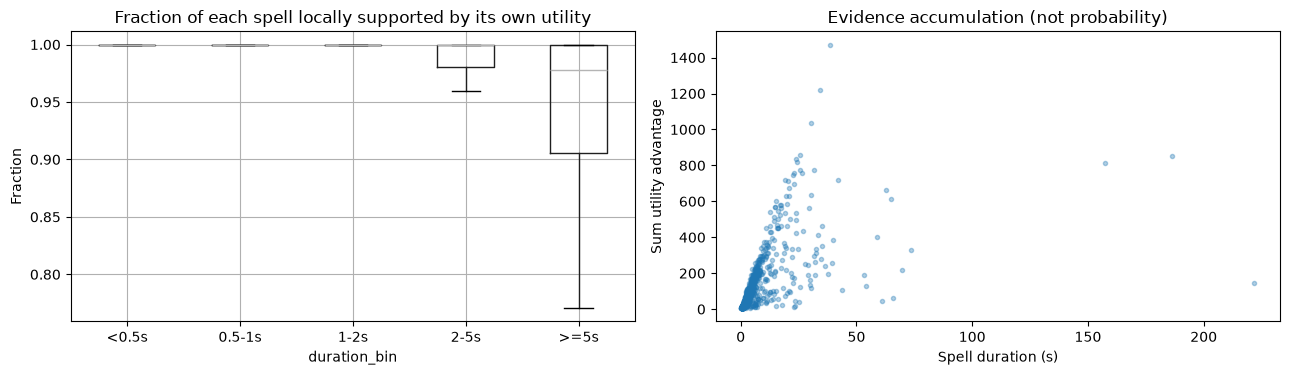

,half,start_frame,end_frame,label,duration_s,observed_fraction,own_preference_fraction,cumulative_advantage,mean_tag_support_difference,mean_proxy_persistence_difference,start_visibility_change
464,1,76248,76258,A,0.44,1.0,1.000000,4.613277,-1.0,0.801653,False
426,1,66297,66311,A,0.60,1.0,1.000000,4.625418,-0.5,0.757576,False
326,1,51983,51993,A,0.44,1.0,1.000000,4.645159,-1.0,0.735537,False
853,2,153624,153634,A,0.44,1.0,1.000000,4.655816,0.5,0.404959,False
786,2,143814,143820,H,0.28,1.0,1.000000,4.661218,-1.0,0.480519,False
707,2,132506,132515,A,0.40,1.0,0.900000,4.731230,-0.5,0.545455,False
91,1,22950,22960,H,0.44,1.0,0.909091,4.749995,-1.0,0.669421,False
74,1,21047,21058,A,0.48,1.0,1.000000,4.756425,-0.5,0.696970,False
557,2,114759,114768,A,0.40,1.0,1.000000,4.760236,0.5,0.345455,False
734,2,134976,134983,H,0.32,1.0,1.000000,4.762407,0.0,0.318182,False


**Temuan run ini:** 1,070 decoded H/A spells, 1,066 reversal dengan ketiga label H/A dan tanpa forced interval; 526 reversal memiliki segmen tengah <2 detik. Rata-rata fraksi bola teramati sepanjang short reversal = 0.998. Angka terakhir adalah rata-rata per-spell, bukan frame-weighted exposure atau accuracy.

**Interpretasi kondisional:** observed_fraction yang mendekati 1 mengarahkan diagnosis ke kestabilan bukti kontrol ketika bola terlihat, bukan missing ball sebagai satu-satunya penjelasan. Jika rendah, periksa perubahan visibility dan kontinuitas bukti terlebih dahulu. Observed tidak otomatis berarti posisi atau identitas tracking benar.

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
rc_spells.boxplot(column="own_preference_fraction",by="duration_bin",ax=axes[0],showfliers=False)
axes[0].set_title("Fraction of each spell locally supported by its own utility");axes[0].set_ylabel("Fraction")
axes[1].scatter(rc_spells.duration_s,rc_spells.cumulative_advantage,s=9,alpha=.35)
axes[1].set(xlabel="Spell duration (s)",ylabel="Sum utility advantage",title="Evidence accumulation (not probability)")
fig.suptitle("");plt.tight_layout();plt.show()
rc_8_reversals=rc_spells.loc[rc_spells.is_reversal & ~rc_spells.any_forced].copy()
rc_8_short=rc_8_reversals.loc[rc_8_reversals.duration_s<2]
display(rc_8_short.sort_values("cumulative_advantage").head(12)[[
    "half","start_frame","end_frame","label","duration_s","observed_fraction",
    "own_preference_fraction","cumulative_advantage","mean_tag_support_difference",
    "mean_proxy_persistence_difference","start_visibility_change"]])
display(Markdown(f"**Temuan run ini:** {len(rc_spells):,} decoded H/A spells, "
    f"{len(rc_8_reversals):,} reversal dengan ketiga label H/A dan tanpa forced interval; "
    f"{len(rc_8_short):,} reversal memiliki segmen tengah <2 detik. "
    f"Rata-rata fraksi bola teramati sepanjang short reversal = {rc_8_short.observed_fraction.mean():.3f}. "
    "Angka terakhir adalah rata-rata per-spell, bukan frame-weighted exposure atau accuracy."))

display(Markdown("**Interpretasi kondisional:** observed_fraction yang mendekati 1 mengarahkan diagnosis "
      "ke kestabilan bukti kontrol ketika bola terlihat, bukan missing ball sebagai satu-satunya penjelasan. "
      "Jika rendah, periksa perubahan visibility dan kontinuitas bukti terlebih dahulu. "
      "Observed tidak otomatis berarti posisi atau identitas tracking benar."))


**Interpretasi dan arah keputusan — Investigasi 8**

| Jika terlihat | Kemungkinan mekanisme | Keputusan berikutnya |
|---|---|---|
| Short spell didukung utility sepanjang segmen dan proxy geometri searah | Decoder mengikuti bukti yang tersedia | Audit makna/kestabilan kontrol, bukan langsung menaikkan penalti |
| Proxy kerap berganti di dalam spell dan dukungan utility sesaat | Bukti kontrol berfluktuasi | Kandidat uji stabilisasi kontrol setelah kontribusi individual diekspos |
| Tag/persistence dan geometri berubah bersama | Sumber bukti berkorelasi | Jangan menyebut double-counting terbukti; perlu instrumentasi kontribusi di src |
| Short reversal sering dimulai saat visibility berubah | Efek pergantian rezim observasi | Bandingkan exposure transisi observed↔missing dan konteks sebelum/sesudah |
| Utility cukup kuat tetapi belum tahu biaya masuk/keluar | Keputusan temporal belum terjelaskan | Lanjut Investigasi 10 |

**Batas simpulan:** tabel ini belum mengidentifikasi sentuhan/rebound vs kontrol sebenarnya. Perbedaan pendek/panjang dapat dipengaruhi fase permainan. `starts_at_visibility_change` adalah proporsi per-spell, bukan normalized switch rate. Perlu exposure rezim sebelum memilih pendekatan quality-aware.


## Investigasi 9 — Validasi peran Smart Tagging dan event anchors

**Pertanyaan:** Apakah konsistensi tag tetap terlihat setelah peran menyerang/bertahan dipisahkan dan proxy yang unavailable dipisahkan dari disagreement?

**Koreksi pembacaan Investigasi 4:** active_h_tags/active_a_tags mencakup seluruh jenis tag; mereka bukan attacking-only tags. Nilai besar utility forced-D bukan evidence alami dari anchor.

**Metode:** klasifikasi semantik kode tag untuk diagnosis (bukan menghitung ulang tag support model), overlay interval [start,end), agreement dengan denominator eksplisit, pemisahan babak/visibility, dan profil event ±5 detik. Seluruh jendela yang melintasi forced-D atau batas babak dikeluarkan. Semua agreement adalah konsistensi antarsinyal otomatis, bukan accuracy.


In [22]:
rc_events9 = read_table(rc_path, "features/initial/events.csv").copy()
rc_attack_codes = {"BUILD UP","PROGRESSION","CREATING CHANCES","LONG BALL","ATTACKING TRANSITION",
                   "BALL IN FINAL THIRD","BALL IN THE BOX","PLAYERS IN THE BOX"}
rc_defence_codes = {"DEFENDING IN ATTACKING THIRD","DEFENDING IN MIDDLE THIRD",
                    "DEFENDING IN DEFENSIVE THIRD","DEFENSIVE TRANSITION"}
def rc_tag_role(code):
    if code in rc_attack_codes: return "attacking_context"
    if code in rc_defence_codes: return "defending_context"
    if code == "SET PIECES": return "set_piece"
    if code == "GOALS": return "goal"
    return "other"
rc_events9["diagnostic_role"] = rc_events9.code_clean.map(rc_tag_role)
display(rc_events9.groupby(["diagnostic_role","code_clean","side"],dropna=False).size().rename("instances").reset_index())
rc_presence = pd.DataFrame({"frame":rc_all.frame.to_numpy()})
for role in ["attacking_context","defending_context"]:
    for side in ["H","A"]:
        presence=np.zeros(len(rc_all),bool)
        subset=rc_events9.loc[rc_events9.diagnostic_role.eq(role)&rc_events9.side.eq(side)]
        for start,end in subset[["start_frame","end_frame"]].itertuples(index=False,name=None):
            start,end=int(start),int(end)
            assert 0 <= start < end <= len(presence), "Invalid event interval"
            presence[start:end]=True  # end exclusive, only diagnostic coverage
        rc_presence[f"{role}_{side}"]=presence
rc_tags9=rc_d.merge(rc_presence,on="frame",how="left",validate="one_to_one")
h=rc_tags9.attacking_context_H;a=rc_tags9.attacking_context_A
rc_tags9["attack_regime"]=np.select([h&~a,a&~h,h&a],["H_only","A_only","both"],default="none")
rc_tags9["single_attack_side"]=np.select([h&~a,a&~h],["H","A"],default="?")
display(rc_tags9.groupby(["half","ball_observed","attack_regime"],observed=True).size().rename("frames").reset_index())
print("H attack with A defence:",int((h & rc_tags9.defending_context_A).sum()))
print("A attack with H defence:",int((a & rc_tags9.defending_context_H).sum()))
print("Unknown-team attacking intervals:",int((rc_events9.diagnostic_role.eq("attacking_context") & ~rc_events9.side.isin(["H","A"])).sum()))


,diagnostic_role,code_clean,side,instances
0,attacking_context,ATTACKING TRANSITION,A,11
1,attacking_context,ATTACKING TRANSITION,H,13
2,attacking_context,BALL IN FINAL THIRD,A,39
3,attacking_context,BALL IN FINAL THIRD,H,54
4,attacking_context,BALL IN THE BOX,A,30
5,attacking_context,BALL IN THE BOX,H,42
6,attacking_context,BUILD UP,A,7
7,attacking_context,BUILD UP,H,15
8,attacking_context,CREATING CHANCES,?,2
9,attacking_context,CREATING CHANCES,A,9


,half,ball_observed,attack_regime,frames
0,1,False,A_only,6379
1,1,False,H_only,10410
2,1,False,both,847
3,1,False,none,14668
4,1,True,A_only,10355
5,1,True,H_only,21331
6,1,True,both,6106
7,1,True,none,9371
8,2,False,A_only,6055
9,2,False,H_only,9391


H attack with A defence: 45316
A attack with H defence: 20904
Unknown-team attacking intervals: 2


,half,ball_observed,attacking_side,frames,proxy_available_frames,proxy_available_fraction,proxy_agreement_available,final_live_frames,final_dead_fraction,final_agreement_all_frames,final_agreement_live_only
0,1,False,A,6379,0,0.0,NaN,6379,0.0,0.994043,0.994043
1,1,False,H,10410,0,0.0,NaN,10410,0.0,1.000000,1.000000
2,1,True,A,10355,10355,1.0,0.561371,10355,0.0,0.602704,0.602704
3,1,True,H,21331,21331,1.0,0.682340,21331,0.0,0.726923,0.726923
4,2,False,A,6055,0,0.0,NaN,6055,0.0,0.999505,0.999505
5,2,False,H,9391,0,0.0,NaN,9391,0.0,0.999894,0.999894
6,2,True,A,12196,12196,1.0,0.629551,12196,0.0,0.662266,0.662266
7,2,True,H,17458,17458,1.0,0.657979,17458,0.0,0.704433,0.704433


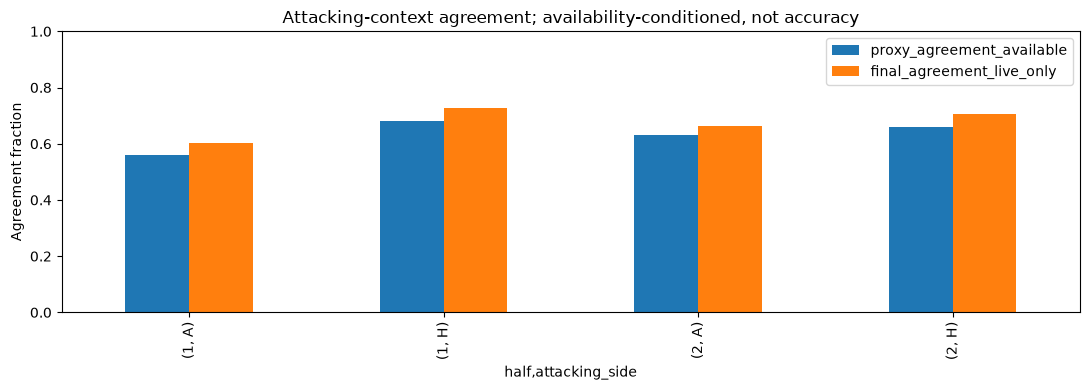

**Cara membaca:** proxy_agreement_available hanya memakai frame dengan proxy H/A. NaN ketika proxy_available_frames=0 berarti tidak terukur, bukan agreement 0%. Attacking-context H dan defending-context A bersamaan bukan otomatis konflik. Klasifikasi kode ini belum mengubah bobot atau pemakaian tag dalam model.

In [23]:
rc_9_agreement_rows=[]
for keys,g in rc_tags9.loc[rc_tags9.single_attack_side.isin(["H","A"])].groupby(
        ["half","ball_observed","single_attack_side"],observed=True):
    half,observed,side=keys
    proxy_ok=g.nearest_team_proxy.isin(["H","A"])
    final_live=g.final_label.isin(["H","A"])
    rc_9_agreement_rows.append({"half":half,"ball_observed":observed,"attacking_side":side,
        "frames":len(g),"proxy_available_frames":int(proxy_ok.sum()),"proxy_available_fraction":proxy_ok.mean(),
        "proxy_agreement_available":g.loc[proxy_ok,"nearest_team_proxy"].eq(side).mean(),
        "final_live_frames":int(final_live.sum()),"final_dead_fraction":g.final_label.eq("D").mean(),
        "final_agreement_all_frames":g.final_label.eq(side).mean(),
        "final_agreement_live_only":g.loc[final_live,"final_label"].eq(side).mean()})
rc_9_agreement=pd.DataFrame(rc_9_agreement_rows)
display(rc_9_agreement)
rc_9_observed=rc_9_agreement.loc[rc_9_agreement.ball_observed & rc_9_agreement.proxy_available_frames.gt(0)]
if len(rc_9_observed):
    rc_9_observed.set_index(["half","attacking_side"])[["proxy_agreement_available","final_agreement_live_only"]].plot.bar(
        ylim=(0,1),figsize=(11,4),title="Attacking-context agreement; availability-conditioned, not accuracy")
    plt.ylabel("Agreement fraction");plt.tight_layout();plt.show()
display(Markdown("**Cara membaca:** proxy_agreement_available hanya memakai frame dengan proxy H/A. "
    "NaN ketika proxy_available_frames=0 berarti tidak terukur, bukan agreement 0%. "
    "Attacking-context H dan defending-context A bersamaan bukan otomatis konflik. "
    "Klasifikasi kode ini belum mengubah bobot atau pemakaian tag dalam model."))


,candidates,unique_frames,median_dead_advantage,max_dead_advantage,D_wins
event,,,,,
set_piece_end,59,59,-1.540561,-0.235068,0
set_piece_start,57,57,-0.250865,-0.032520,0


Excluded candidate windows:


,event,reason,count
0,set_piece_end,cross_half_or_ungraded,1
1,set_piece_end,touches_forced_D,1
2,set_piece_start,touches_forced_D,1


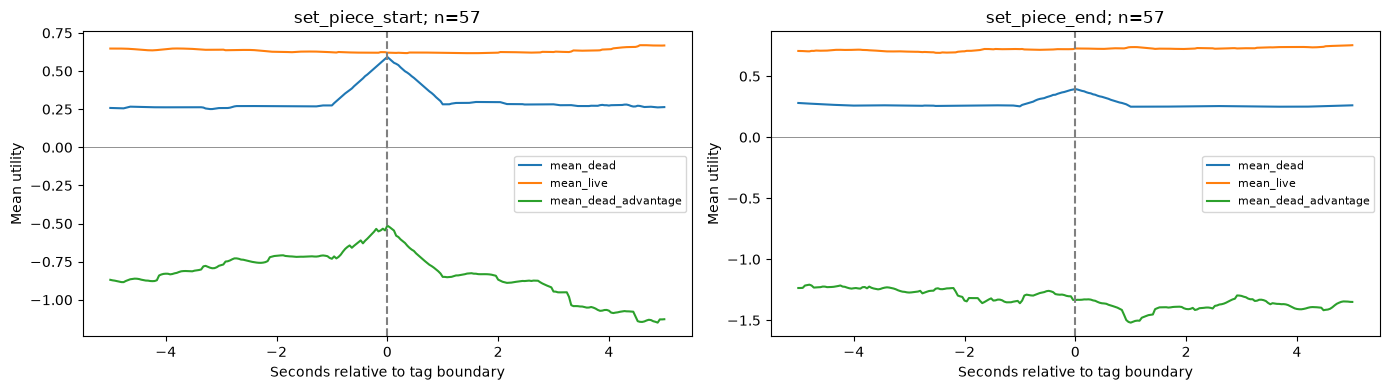

**Temuan run ini:** 116 candidate records berada pada frame alami graded dari 117 total records. Profil hanya memakai jendela penuh dalam satu babak tanpa forced-D. Perbedaan profil start/end bukan estimasi efek kausal anchor: konteks, observability, dan event yang tumpang tindih dapat berbeda.

In [24]:
rc_candidates9=read_table(rc_path,f"core/{rc_pass}/events/candidates.csv")
rc_annotated9=rc_candidates9.merge(rc_all[["frame","half","graded","forced_d","dead_advantage", "dead_score", "live_score"]],
    on="frame",how="left",validate="many_to_one",indicator=True)
assert rc_annotated9["_merge"].eq("both").all()
rc_natural_candidates9=rc_annotated9.loc[rc_annotated9.graded & ~rc_annotated9.forced_d]
display(rc_natural_candidates9.groupby("event").agg(candidates=("frame","size"),unique_frames=("frame","nunique"),
    median_dead_advantage=("dead_advantage","median"),max_dead_advantage=("dead_advantage","max"),
    D_wins=("dead_advantage",lambda s:int((s>1e-9).sum()))))
rc_profile_rows=[];rc_profile_exclusions=[]
rc_offsets=np.arange(-int(5*rc_fps),int(5*rc_fps)+1)
for r in rc_candidates9.itertuples(index=False):
    idx=int(r.frame)+rc_offsets;reason=None
    if idx.min()<0 or idx.max()>=len(rc_all):
        reason="outside_video"
    else:
        window=rc_all.iloc[idx]
        if not window.graded.all() or not window.half.eq(window.half.iloc[0]).all():reason="cross_half_or_ungraded"
        elif window.forced_d.any():reason="touches_forced_D"
    if reason:
        rc_profile_exclusions.append({"event":r.event,"reason":reason});continue
    assert np.array_equal(window.frame.to_numpy(),idx)
    for offset,(_,row) in zip(rc_offsets,window.iterrows()):
        rc_profile_rows.append({"event":r.event,"offset_s":offset/rc_fps,
            "dead_score":row.dead_score,"live_score":row.live_score,"dead_advantage":row.dead_advantage})
rc_profile9=pd.DataFrame(rc_profile_rows)
rc_profile_summary9=rc_profile9.groupby(["event","offset_s"]).agg(
    anchors=("dead_score","size"),mean_dead=("dead_score","mean"),
    mean_live=("live_score","mean"),mean_dead_advantage=("dead_advantage","mean")).reset_index()
print("Excluded candidate windows:")
display(pd.DataFrame(rc_profile_exclusions).groupby(["event","reason"]).size().rename("count").reset_index())
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,event in zip(axes,["set_piece_start","set_piece_end"]):
    z=rc_profile_summary9.loc[rc_profile_summary9.event.eq(event)]
    for column in ["mean_dead","mean_live","mean_dead_advantage"]:ax.plot(z.offset_s,z[column],label=column)
    ax.axvline(0,color="gray",ls="--");ax.axhline(0,color="gray",lw=.6)
    ax.set(title=f"{event}; n={int(z.anchors.iloc[0]) if len(z) else 0}",xlabel="Seconds relative to tag boundary",ylabel="Mean utility")
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(Markdown(f"**Temuan run ini:** {len(rc_natural_candidates9):,} candidate records berada pada frame alami graded "
    f"dari {len(rc_candidates9):,} total records. Profil hanya memakai jendela penuh dalam satu babak tanpa forced-D. "
    "Perbedaan profil start/end bukan estimasi efek kausal anchor: konteks, observability, dan event yang tumpang tindih dapat berbeda."))


**Interpretasi dan arah keputusan — Investigasi 9**

| Jika terlihat | Kemungkinan mekanisme | Keputusan berikutnya |
|---|---|---|
| Agreement berubah setelah defending tags dipisahkan | Kelompok lama tidak sesuai makna attacking | Revisi pembacaan Investigasi 4; belum perlu ubah model |
| Agreement proxy naik setelah unavailable dikeluarkan | Availability mencampuri pengukuran lama | Pertahankan denominator eksplisit; jangan klaim accuracy naik |
| Tag mendukung tim saat bola missing | Sumber konteks tersedia | Audit durasi dan konflik tag; tidak otomatis menjadikannya label |
| Attacking H dan attacking A bertumpang tindih | Bukti berpotensi ambigu | Periksa keluarga tag, overlap, dan kontribusi model sebelum mengubah bobot |
| D naik hanya tepat di sekitar batas tag | Pulsa terlalu lokal untuk mewakili interval | Kandidat eksperimen evidence temporal, setelah Investigasi 7 |
| D tetap kalah di sekitar anchor | Efek event tidak cukup untuk memenangkan fusion | Gabungkan dengan dekomposisi skor; jangan langsung memperbesar anchor |

**Batas simpulan:** side pada tag adalah pelaku event, bukan selalu pemilik bola. Start/end tag bukan restart ground truth. Profil event adalah agregat observasional dengan kandidat otomatis yang bisa berkorelasi/duplikat.


## Investigasi 10 — Audit keuntungan utility vs biaya dua transisi

**Pertanyaan:** Mengapa decoder mempertahankan H-A-H/A-H-A tertentu? Apakah keuntungan mempertahankan segmen tengah mengatasi biaya masuk dan keluar?

**Data:** decoded spells, utility dan transition/stop/restart hints dari pass yang sama. **Metode:** panggil `state_cost_matrix` dan `transition_costs` asli di src, setelah hash kodenya cocok dengan canonical run. Tidak menyalin rumus biaya atau menjalankan decoder baru.

Untuk kandidat reversal dengan outer label sama, perbandingan lokalnya adalah:

`net_gain = sum(utility_middle - utility_outer) - entry_cost - exit_cost`.

Entry memakai hint pada `start_frame`; exit pada `end_frame+1`. Label luar dan bagian urutan lain dianggap tetap. Ini menjelaskan objective lokal, bukan memastikan possession tersebut benar. Post-Viterbi merge dan boundary refinement harus dipisahkan dari pemeriksaan optimalitas Viterbi.


In [25]:
from src.temporal_decoder import state_cost_matrix, transition_costs
rc_source_hashes={k.replace("\\","/"):v for k,v in rc_manifest["source_sha256"].items()}
rc_decoder_source=RC_ROOT/"src/temporal_decoder.py"
assert hashlib.sha256(rc_decoder_source.read_bytes()).hexdigest()==rc_source_hashes["src/temporal_decoder.py"],     "Decoder source differs from run; do not audit old run using new transition logic"
rc_hints10=rc_all[["frame"]].copy()
for name in ["transition_hint","stop_hint","restart_hint"]:
    rc_hints10=rc_join(rc_hints10,f"core/{rc_pass}/fusion/{name}.csv")
rc_hints10=rc_hints10.set_index("frame")
rc_temporal=rc_cfg["temporal"]
rc_base_cost=state_cost_matrix(rc_temporal)
rc_state_index={"H":0,"A":1,"D":2}
rc_soft_scale=int(rc_temporal["short_spell_scale_frames"])
rc_decode_diag=read_json(rc_path,f"core/{rc_pass}/decode/diagnostics.json")
rc_cost_rows=[]
for r in rc_8_reversals.itertuples(index=False):
    start,end=int(r.start_frame),int(r.end_frame)
    assert rc_all.iloc[start:end+1].decoded_label.eq(r.label).all()
    assert rc_all.iloc[start-1].decoded_label==r.outer_label
    assert rc_all.iloc[end+1].decoded_label==r.outer_label
    assert rc_all.iloc[start-1].half==r.half==rc_all.iloc[end+1].half
    incoming=rc_hints10.loc[start];outgoing=rc_hints10.loc[end+1]
    entry_matrix=transition_costs(rc_base_cost,float(incoming.transition_hint),float(incoming.stop_hint),float(incoming.restart_hint),rc_temporal)
    exit_matrix=transition_costs(rc_base_cost,float(outgoing.transition_hint),float(outgoing.stop_hint),float(outgoing.restart_hint),rc_temporal)
    outer,middle=rc_state_index[r.outer_label],rc_state_index[r.label]
    entry,exit=float(entry_matrix[outer,middle]),float(exit_matrix[middle,outer])
    cost=entry+exit;gain=float(r.cumulative_advantage)
    rc_cost_rows.append({"half":r.half,"start_frame":start,"end_frame":end,"middle":r.label,
        "outer":r.outer_label,"duration_s":r.duration_s,"n_frames":r.n_frames,
        "cumulative_advantage":gain,"entry_cost":entry,"exit_cost":exit,"two_transition_cost":cost,
        "net_gain":gain-cost,"gain_cost_ratio":gain/cost if cost>0 else np.nan,
        "entry_turnover_hint":float(incoming.transition_hint),"exit_turnover_hint":float(outgoing.transition_hint),
        "observed_fraction":r.observed_fraction,"within_soft_scale":r.n_frames<rc_soft_scale})
rc_cost_audit=pd.DataFrame(rc_cost_rows)
rc_cost_audit["duration_bin"]=pd.cut(rc_cost_audit.duration_s,[0,.5,1,2,5,np.inf],
    labels=["<0.5s","0.5-1s","1-2s","2-5s",">=5s"],right=False)
display(rc_cost_audit.groupby("duration_bin",observed=True).agg(
    reversals=("start_frame","size"),median_gain=("cumulative_advantage","median"),
    median_cost=("two_transition_cost","median"),median_net_gain=("net_gain","median"),
    p05_gain_cost_ratio=("gain_cost_ratio",lambda s:s.quantile(.05)),median_gain_cost_ratio=("gain_cost_ratio","median"),
    within_soft_scale=("within_soft_scale","sum")))
print("Soft-scale frames:",rc_soft_scale,"seconds:",rc_soft_scale/rc_fps,"explicit merges:",rc_decode_diag["short_runs_merged"])
rc_negative10=rc_cost_audit.loc[rc_cost_audit.net_gain < -1e-7]
print("Negative local net gain candidates:",len(rc_negative10))
display(rc_cost_audit.sort_values("net_gain").head(15))


,reversals,median_gain,median_cost,median_net_gain,p05_gain_cost_ratio,median_gain_cost_ratio,within_soft_scale
duration_bin,,,,,,,
<0.5s,80,5.914245,4.495903,1.377866,1.050222,1.305342,50
0.5-1s,231,10.280036,4.540701,5.751932,1.187965,2.267396,0
1-2s,215,26.017210,4.554110,21.500576,2.481809,5.760310,0
2-5s,245,71.683310,4.560147,67.145297,5.200330,15.705118,0
>=5s,295,204.267421,4.592881,199.550446,6.965402,44.244369,0


Soft-scale frames: 12 seconds: 0.48 explicit merges: 0
Negative local net gain candidates: 0


,half,start_frame,end_frame,middle,outer,duration_s,n_frames,cumulative_advantage,entry_cost,exit_cost,two_transition_cost,net_gain,gain_cost_ratio,entry_turnover_hint,exit_turnover_hint,observed_fraction,within_soft_scale,duration_bin
425,1,66297,66311,A,H,0.60,15,4.625418,2.306353,2.314903,4.621256,0.004163,1.000901,0.117059,0.106372,1.0,False,0.5-1s
463,1,76248,76258,A,H,0.44,11,4.613277,2.285314,2.283847,4.569162,0.044116,1.009655,0.143357,0.145191,1.0,True,<0.5s
850,2,153624,153634,A,H,0.44,11,4.655816,2.270173,2.293306,4.563480,0.092336,1.020234,0.162283,0.133367,1.0,True,<0.5s
325,1,51983,51993,A,H,0.44,11,4.645159,2.263665,2.262757,4.526421,0.118738,1.026232,0.170419,0.171554,1.0,True,<0.5s
484,1,79130,79142,H,A,0.52,13,4.765248,2.313654,2.299623,4.613278,0.151970,1.032942,0.107932,0.125471,1.0,False,0.5-1s
127,1,26528,26547,A,H,0.80,20,4.847248,2.332779,2.337040,4.669818,0.177430,1.037995,0.084027,0.078700,1.0,False,0.5-1s
125,1,26392,26405,A,H,0.56,14,4.791775,2.304788,2.297201,4.601989,0.189787,1.041240,0.119015,0.128499,1.0,False,0.5-1s
73,1,21047,21058,A,H,0.48,12,4.756425,2.270853,2.274422,4.545275,0.211150,1.046455,0.161433,0.156973,1.0,False,<0.5s
90,1,22950,22960,H,A,0.44,11,4.749995,2.268457,2.253536,4.521993,0.228002,1.050421,0.164428,0.183080,1.0,True,<0.5s
704,2,132506,132515,A,H,0.40,10,4.731230,2.255527,2.235221,4.490748,0.240482,1.053551,0.180591,0.205974,1.0,True,<0.5s


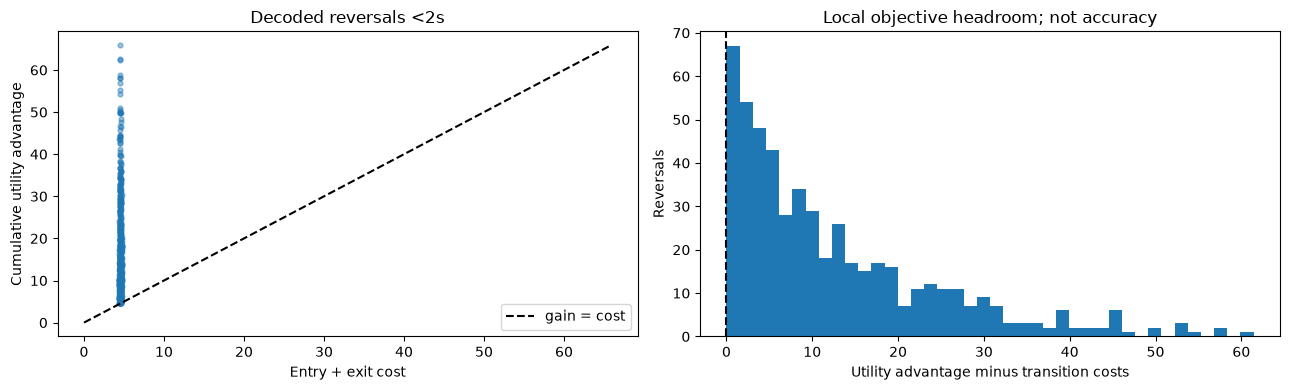

**Temuan run ini:** 1,066 decoded reversals diperiksa; 50 memiliki n_frames di bawah soft scale 12 frame (0.48 detik). Explicit short-run merges pada artefak = 0. Tidak ada kontradiksi net gain negatif pada kandidat yang diperiksa; ini konsisten dengan keputusan decoder, bukan bukti label benar. Ambang diagnosis <2 detik berbeda dari soft scale model. Jika explicit merges >0, decoded labels merupakan hasil postprocessing dan tidak cukup untuk menguji optimalitas raw Viterbi.

In [26]:
rc_short_cost10=rc_cost_audit.loc[rc_cost_audit.duration_s<2]
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].scatter(rc_short_cost10.two_transition_cost,rc_short_cost10.cumulative_advantage,s=12,alpha=.45)
upper=max(rc_short_cost10.two_transition_cost.max(),rc_short_cost10.cumulative_advantage.max())
axes[0].plot([0,upper],[0,upper],ls="--",color="black",label="gain = cost")
axes[0].set(xlabel="Entry + exit cost",ylabel="Cumulative utility advantage",title="Decoded reversals <2s")
axes[0].legend()
axes[1].hist(rc_short_cost10.net_gain,bins=40)
axes[1].axvline(0,color="black",ls="--")
axes[1].set(xlabel="Utility advantage minus transition costs",ylabel="Reversals",title="Local objective headroom; not accuracy")
plt.tight_layout();plt.show()
rc_10_eligible=int(rc_cost_audit.within_soft_scale.sum())
rc_10_negative=len(rc_negative10)
rc_10_note=("Ada kandidat dengan net gain negatif: periksa alignment, biaya pada frame yang tepat, versi kode, dan postprocessing sebelum menyebut bug."
    if rc_10_negative else "Tidak ada kontradiksi net gain negatif pada kandidat yang diperiksa; ini konsisten dengan keputusan decoder, bukan bukti label benar.")
display(Markdown(f"**Temuan run ini:** {len(rc_cost_audit):,} decoded reversals diperiksa; "
    f"{rc_10_eligible:,} memiliki n_frames di bawah soft scale {rc_soft_scale} frame ({rc_soft_scale/rc_fps:.2f} detik). "
    f"Explicit short-run merges pada artefak = {rc_decode_diag['short_runs_merged']}. {rc_10_note} "
    "Ambang diagnosis <2 detik berbeda dari soft scale model. Jika explicit merges >0, decoded labels merupakan hasil postprocessing dan tidak cukup untuk menguji optimalitas raw Viterbi."))


**Interpretasi dan arah keputusan — Investigasi 10**

| Jika terlihat | Kemungkinan mekanisme | Keputusan berikutnya |
|---|---|---|
| Gain jauh di atas dua biaya transisi | Skor mendukung segmen tengah dengan kuat | Audit scoring/kontrol dan persistensi; menaikkan cost saja belum menjelaskan penyebab |
| Gain hanya sedikit di atas biaya | Keputusan sensitif terhadap skala biaya | Kandidat eksperimen biaya satu-variabel dengan skenario sintetis |
| Banyak short spells berada di luar soft scale | Postprocessor tidak ditujukan untuk seluruh kategori <2s | Jangan menafsirkan zero merges sebagai tidak adanya regularisasi temporal |
| Net gain negatif ketika raw Viterbi seharusnya optimal | Kemungkinan masalah audit/indeks/postprocessing atau implementasi | Verifikasi dahulu; jangan menyebut bug berdasarkan tabel tunggal |
| Count tetap setelah refinement | Refinement mengatur posisi, bukan jumlah spell | Pisahkan eksperimen boundary dari eksperimen fragmentasi |

**Batas simpulan:** audit mengganti hanya segmen tengah dengan outer label, sementara label lain tetap. Ia tidak mengevaluasi semua alternatif jalur atau ketepatan pertandingan. Nilai utility dijumlahkan per frame yang berkorelasi; rasio gain/cost bukan confidence.

**Arah setelah investigasi 7–10:** pilih satu mekanisme paling spesifik untuk diuji. Catat hipotesis di Investigasi 6, buat satu perubahan di src/config model, hasilkan run baru, dan bandingkan perilaku serta skenario sintetis. Jangan memilih parameter berdasarkan public GT atau mengejar jumlah possession tertentu.
